# 🚕 Taxis NYC — Preparación del modelo

## Serie horaria de demanda y primer modelo de pronóstico

**Proyecto:** AIMLF1 · Módulo 2  
**Integrantes:** *Leonardo Isai Zepeda Tolentino*

---

### Objetivo de esta primera etapa

En esta primera fase se construirá la base técnica del proyecto:

1. Cargar los viajes oficiales de taxis amarillos de Nueva York correspondientes a enero de 2024.
2. Limpiar los registros y conservar únicamente viajes válidos.
3. Seleccionar las zonas con al menos **3,000 viajes durante el mes**.
4. Transformar los viajes individuales en una **serie horaria por zona**.
5. Completar explícitamente las horas sin viajes con valor `0`.
6. Construir un modelo base: **“igual que hace una semana”**.
7. Entrenar un primer modelo sencillo con **XGBoost**.
8. Evaluar ambos modelos respetando el orden temporal de los datos.
9. Exportar la información de las zonas que utilizará posteriormente el endpoint `/info` de FastAPI.

> En esta etapa todavía **no** se implementan los cuantiles definitivos, K-Means, PCA ni Streamlit. Primero se valida que la preparación de datos y el flujo de pronóstico funcionen correctamente.


## 1. Criterios metodológicos

Para mantener el análisis reproducible y evitar fuga de información se seguirán estas decisiones:

- **Semilla reproducible:** `RANDOM_STATE = 42`.
- **Entrenamiento:** datos disponibles hasta el **24 de enero de 2024**.
- **Prueba:** del **25 al 31 de enero de 2024**.
- **No se utiliza `train_test_split`**, porque el problema es temporal.
- El primer baseline será `lag_168`, equivalente a utilizar la demanda observada exactamente una semana antes.
- No se utilizan lags menores a 24 horas para un pronóstico del día siguiente.
- El conjunto de prueba se mantiene separado para medir el rendimiento real del modelo.

### ¿Por qué `random_state = 42`?

La semilla no se elige para obtener la mejor métrica. Su función es hacer reproducibles los procesos que contienen aleatoriedad, de modo que los integrantes del proyecto obtengan los mismos resultados cuando ejecuten el notebook nuevamente.


In [1]:
# ============================================================
# 0. INSTALACIÓN DE DEPENDENCIAS
# ============================================================
# Esta celda está pensada principalmente para Google Colab.
# Si las librerías ya están instaladas, pip simplemente validará
# o actualizará las dependencias necesarias.

%pip -q install xgboost pyarrow


In [2]:
# ============================================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# ============================================================

# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Modelo inicial de Machine Learning
from xgboost import XGBRegressor

# Métricas de evaluación para regresión
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Configuración visual general
sns.set_theme(style="whitegrid")

# Semilla global para procesos con aleatoriedad.
# Se mantiene fija para garantizar reproducibilidad.
RANDOM_STATE = 42

print("Librerías importadas correctamente.")
print("RANDOM_STATE =", RANDOM_STATE)


Librerías importadas correctamente.
RANDOM_STATE = 42


## 2. Configuración general

En lugar de escribir fechas y límites repetidamente dentro del código, se definen como constantes al inicio del notebook. Esto facilita el mantenimiento y reduce errores.

Las reglas principales de esta actividad son:

- Solo se consideran viajes cuyo inicio ocurrió dentro de enero de 2024.
- La zona de un viaje corresponde a `PULocationID`.
- Para el pronóstico se consideran zonas con al menos **3,000 viajes** durante el mes.
- El conjunto de entrenamiento termina el **24 de enero**.
- El conjunto de prueba corresponde al período **25–31 de enero**.


In [3]:
# ============================================================
# 2. CONFIGURACIÓN GENERAL DEL PROYECTO
# ============================================================

# Dataset oficial de taxis amarillos de enero de 2024.
URL_VIAJES = (
    "https://d37ci6vzurychx.cloudfront.net/"
    "trip-data/yellow_tripdata_2024-01.parquet"
)

# Catálogo oficial con los nombres y distritos de las zonas.
URL_ZONAS = (
    "https://d37ci6vzurychx.cloudfront.net/"
    "misc/taxi_zone_lookup.csv"
)

# Fechas del análisis.
FECHA_INICIO = pd.Timestamp("2024-01-01")
FECHA_FIN_ENERO = pd.Timestamp("2024-02-01")

# Inicio del conjunto de prueba.
# Todo lo anterior corresponde al entrenamiento.
FECHA_INICIO_TEST = pd.Timestamp("2024-01-25")

# Cantidad mínima de viajes para que una zona
# participe en el modelo de pronóstico.
MIN_VIAJES_PRONOSTICO = 3000

print("Configuración cargada correctamente.")


Configuración cargada correctamente.


## 3. Carga de los datos

Para construir la serie temporal únicamente se necesitan dos columnas del archivo principal:

- `tpep_pickup_datetime`: fecha y hora de inicio del viaje.
- `PULocationID`: identificador de la zona donde comenzó el viaje.

Leer únicamente estas columnas reduce el consumo de memoria RAM.

El catálogo de zonas se carga por separado para traducir los identificadores a nombres comprensibles.


In [4]:
# ============================================================
# 3. CARGA DE LOS DATOS
# ============================================================

# Columnas necesarias en esta primera etapa.
columnas_necesarias = [
    "tpep_pickup_datetime",
    "PULocationID"
]

# Leemos el archivo Parquet oficial.
# El formato Parquet permite seleccionar columnas y es más eficiente
# para datasets grandes que un CSV tradicional.
viajes = pd.read_parquet(
    URL_VIAJES,
    columns=columnas_necesarias
)

# Catálogo oficial de zonas de taxi.
zonas = pd.read_csv(URL_ZONAS)

print(f"Viajes cargados: {len(viajes):,}")
print(f"Zonas registradas en el catálogo: {len(zonas):,}")


Viajes cargados: 2,964,624
Zonas registradas en el catálogo: 265


In [5]:
# ============================================================
# 4. INSPECCIÓN INICIAL
# ============================================================

print("Primeros registros del dataset de viajes:")
display(viajes.head())

print("\nInformación general del dataset:")
viajes.info()

print("\nPrimeras zonas del catálogo:")
display(zonas.head())


Primeros registros del dataset de viajes:


,tpep_pickup_datetime,PULocationID
0,2024-01-01 00:57:55,186
1,2024-01-01 00:03:00,140
2,2024-01-01 00:17:06,236
3,2024-01-01 00:36:38,79
4,2024-01-01 00:46:51,211



Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2964624 entries, 0 to 2964623
Data columns (total 2 columns):
 #   Column                Dtype         
---  ------                -----         
 0   tpep_pickup_datetime  datetime64[us]
 1   PULocationID          int32         
dtypes: datetime64[us](1), int32(1)
memory usage: 33.9 MB

Primeras zonas del catálogo:


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


## 4. Limpieza temporal

Aunque el archivo corresponde a enero de 2024, se valida explícitamente la fecha de inicio de cada viaje.

Esto evita conservar registros cuya fecha pueda encontrarse fuera del período requerido.

También se utiliza `errors="coerce"` para convertir valores de fecha inválidos en `NaT`, de modo que puedan descartarse de forma segura.


In [6]:
# ============================================================
# 5. LIMPIEZA TEMPORAL
# ============================================================

# Convertimos la columna de fecha al tipo datetime.
viajes["tpep_pickup_datetime"] = pd.to_datetime(
    viajes["tpep_pickup_datetime"],
    errors="coerce"
)

viajes_antes = len(viajes)

# Conservamos únicamente viajes cuyo inicio ocurrió
# dentro de enero de 2024.
viajes = viajes[
    (viajes["tpep_pickup_datetime"] >= FECHA_INICIO) &
    (viajes["tpep_pickup_datetime"] < FECHA_FIN_ENERO)
].copy()

print(f"Registros antes del filtro: {viajes_antes:,}")
print(f"Viajes válidos de enero:    {len(viajes):,}")
print(f"Registros descartados:      {viajes_antes - len(viajes):,}")


Registros antes del filtro: 2,964,624
Viajes válidos de enero:    2,964,606
Registros descartados:      18


## 5. Incorporación del catálogo de zonas

La actividad define la zona de cada viaje mediante `PULocationID`, es decir, **la zona de origen**.

Se realiza un `merge` con el catálogo oficial para incorporar:

- nombre de la zona;
- distrito (`Borough`).

Posteriormente se eliminan las zonas sin identificación válida o denominadas `"Unknown"`.


In [7]:
# ============================================================
# 6. INCORPORACIÓN DEL CATÁLOGO DE ZONAS
# ============================================================

# Seleccionamos solo las columnas que necesitamos.
catalogo = zonas[
    ["LocationID", "Borough", "Zone"]
].copy()

# Relacionamos PULocationID con LocationID.
viajes = viajes.merge(
    catalogo,
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
)

# Renombramos las columnas para hacer el código más legible.
viajes = viajes.rename(
    columns={
        "Zone": "nombre_zona",
        "Borough": "distrito"
    }
)

# Eliminamos zonas sin nombre y las llamadas "Unknown".
viajes = viajes[
    viajes["nombre_zona"].notna() &
    (viajes["nombre_zona"].astype(str).str.strip().str.lower() != "unknown")
].copy()

print(f"Viajes después de eliminar zonas no identificadas: {len(viajes):,}")

display(
    viajes[
        [
            "tpep_pickup_datetime",
            "PULocationID",
            "nombre_zona",
            "distrito"
        ]
    ].head()
)


Viajes después de eliminar zonas no identificadas: 2,954,246


,tpep_pickup_datetime,PULocationID,nombre_zona,distrito
0,2024-01-01 00:57:55,186,Penn Station/Madison Sq West,Manhattan
1,2024-01-01 00:03:00,140,Lenox Hill East,Manhattan
2,2024-01-01 00:17:06,236,Upper East Side North,Manhattan
3,2024-01-01 00:36:38,79,East Village,Manhattan
4,2024-01-01 00:46:51,211,SoHo,Manhattan


## 6. Selección de zonas pronosticables

No todas las zonas tienen suficiente actividad para construir un modelo de demanda estable.

La regla del proyecto indica conservar para el pronóstico solamente aquellas zonas que registraron al menos **3,000 viajes durante enero**.


In [8]:
# ============================================================
# 7. CONTEO DE VIAJES POR ZONA
# ============================================================

conteo_zonas = (
    viajes.groupby(
        ["PULocationID", "nombre_zona", "distrito"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "total_viajes"})
)

# Aplicamos el límite mínimo establecido.
zonas_pronostico = conteo_zonas[
    conteo_zonas["total_viajes"] >= MIN_VIAJES_PRONOSTICO
].copy()

zonas_pronostico = zonas_pronostico.sort_values(
    "total_viajes",
    ascending=False
)

print(f"Zonas con al menos {MIN_VIAJES_PRONOSTICO:,} viajes: "
      f"{len(zonas_pronostico)}")

display(zonas_pronostico.head(15))


Zonas con al menos 3,000 viajes: 58


,PULocationID,nombre_zona,distrito,total_viajes
126,132,JFK Airport,Queens,145240
155,161,Midtown Center,Manhattan,143469
231,237,Upper East Side South,Manhattan,142707
230,236,Upper East Side North,Manhattan,136464
156,162,Midtown East,Manhattan,106717
224,230,Times Sq/Theatre District,Manhattan,106324
180,186,Penn Station/Madison Sq West,Manhattan,104522
136,142,Lincoln Square East,Manhattan,104080
132,138,LaGuardia Airport,Queens,89530
233,239,Upper West Side South,Manhattan,88474


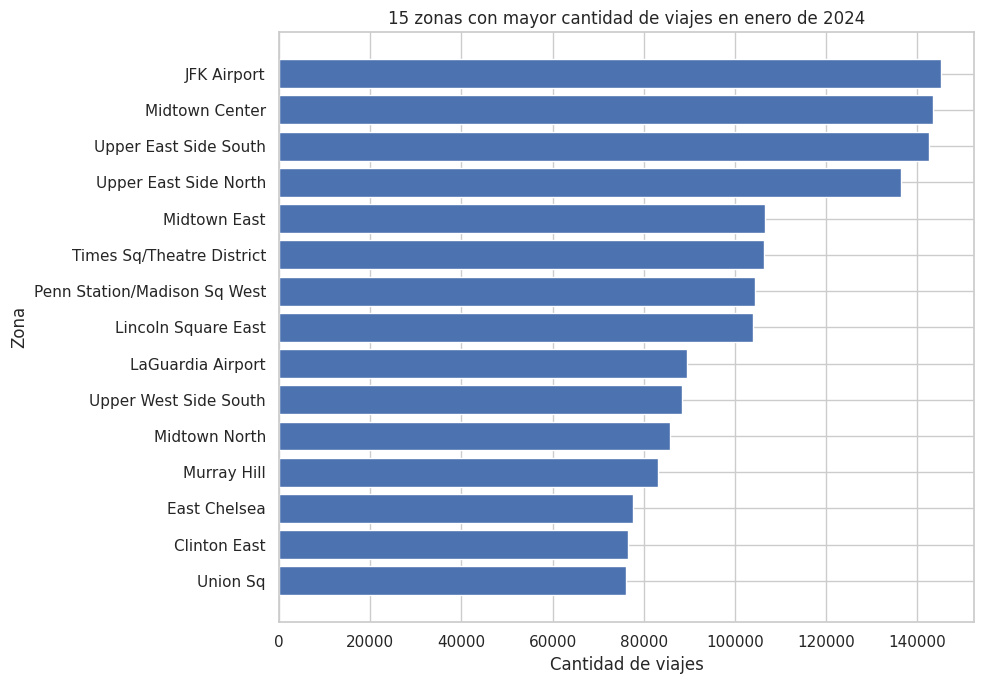

In [9]:
# ============================================================
# 8. VISUALIZACIÓN DE LAS ZONAS CON MAYOR DEMANDA
# ============================================================

top_zonas = zonas_pronostico.head(15).sort_values(
    "total_viajes",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_zonas["nombre_zona"],
    top_zonas["total_viajes"]
)
plt.title("15 zonas con mayor cantidad de viajes en enero de 2024")
plt.xlabel("Cantidad de viajes")
plt.ylabel("Zona")
plt.tight_layout()
plt.show()


### Análisis

La demanda se concentra principalmente en **Manhattan** y en los aeropuertos. **JFK Airport** registra la mayor cantidad de viajes del mes, seguido por zonas como Midtown Center y Upper East Side South. Esto muestra que la actividad del taxi amarillo no está distribuida de forma uniforme y que ciertas zonas concentran una parte importante de la demanda.


## 7. Construcción de la serie horaria

Los viajes individuales deben convertirse en una serie temporal de demanda.

El procedimiento es:

1. Redondear la fecha de inicio hacia abajo a la hora completa.
2. Contar cuántos viajes comenzaron en cada zona durante cada hora.
3. Crear todas las combinaciones posibles entre zona y hora.
4. Asignar `0` cuando una combinación zona-hora no aparezca en los viajes observados.

Este último punto es importante: la ausencia de una fila no significa que la demanda sea desconocida; significa que durante esa hora hubo **cero viajes**.


In [10]:
# ============================================================
# 9. FILTRADO DE VIAJES PARA LAS ZONAS PRONOSTICABLES
# ============================================================

# Lista de identificadores que sí participarán en el modelo.
ids_zonas = zonas_pronostico["PULocationID"].tolist()

viajes_modelo = viajes[
    viajes["PULocationID"].isin(ids_zonas)
].copy()

print(f"Viajes que participarán en la serie horaria: "
      f"{len(viajes_modelo):,}")


Viajes que participarán en la serie horaria: 2,885,953


In [11]:
# ============================================================
# 10. AGRUPACIÓN POR ZONA Y HORA
# ============================================================

# floor("h") redondea la hora hacia abajo.
#
# Ejemplo:
# 2024-01-05 14:37:20 -> 2024-01-05 14:00:00
viajes_modelo["hora"] = (
    viajes_modelo["tpep_pickup_datetime"]
    .dt.floor("h")
)

# Contamos la cantidad de viajes en cada combinación zona-hora.
demanda_observada = (
    viajes_modelo
    .groupby(["PULocationID", "hora"])
    .size()
    .reset_index(name="viajes")
)

print(f"Combinaciones zona-hora observadas: "
      f"{len(demanda_observada):,}")

display(demanda_observada.head())


Combinaciones zona-hora observadas: 41,359


,PULocationID,hora,viajes
0,4,2024-01-01 00:00:00,25
1,4,2024-01-01 01:00:00,29
2,4,2024-01-01 02:00:00,34
3,4,2024-01-01 03:00:00,31
4,4,2024-01-01 04:00:00,32


In [12]:
# ============================================================
# 11. COMPLETAR LAS HORAS SIN VIAJES
# ============================================================

# Enero de 2024 tiene:
# 31 días × 24 horas = 744 horas.
horas_enero = pd.date_range(
    start="2024-01-01 00:00:00",
    end="2024-01-31 23:00:00",
    freq="h"
)

# Creamos el producto cartesiano:
# cada zona × cada hora de enero.
indice_completo = pd.MultiIndex.from_product(
    [ids_zonas, horas_enero],
    names=["PULocationID", "hora"]
)

# Reindexamos la demanda observada.
# fill_value=0 coloca cero viajes en las horas que no aparecían.
demanda = (
    demanda_observada
    .set_index(["PULocationID", "hora"])
    .reindex(indice_completo, fill_value=0)
    .reset_index()
)

print(f"Filas finales de la serie horaria: {len(demanda):,}")
display(demanda.head())


Filas finales de la serie horaria: 43,152


,PULocationID,hora,viajes
0,132,2024-01-01 00:00:00,150
1,132,2024-01-01 01:00:00,68
2,132,2024-01-01 02:00:00,21
3,132,2024-01-01 03:00:00,18
4,132,2024-01-01 04:00:00,26


In [13]:
# ============================================================
# 12. VERIFICACIONES DE CALIDAD DE LA SERIE HORARIA
# ============================================================

horas_por_zona = (
    demanda.groupby("PULocationID")["hora"]
    .count()
)

print("Horas mínimas por zona:", horas_por_zona.min())
print("Horas máximas por zona:", horas_por_zona.max())

print("\nValores faltantes:")
display(demanda.isna().sum())

# Comprobación explícita.
assert horas_por_zona.min() == 744
assert horas_por_zona.max() == 744
assert demanda["viajes"].isna().sum() == 0

print("\n✅ La serie horaria está completa: 744 horas por zona.")


Horas mínimas por zona: 744
Horas máximas por zona: 744

Valores faltantes:


,0
PULocationID,0
hora,0
viajes,0



✅ La serie horaria está completa: 744 horas por zona.


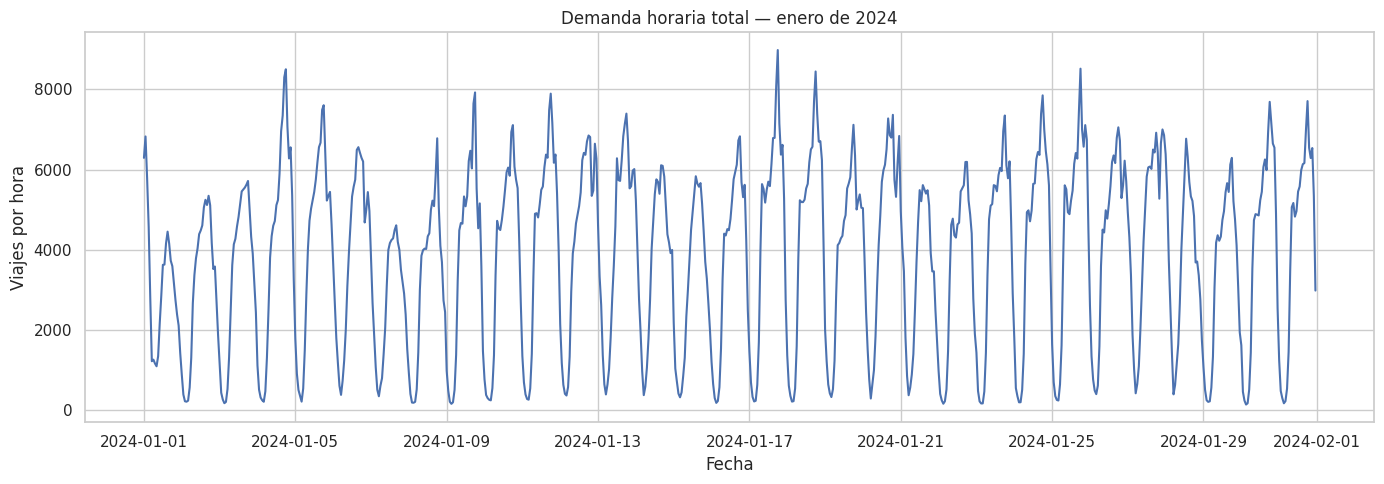

In [14]:
# ============================================================
# 13. COMPORTAMIENTO GENERAL DE LA DEMANDA
# ============================================================

# Sumamos la demanda de todas las zonas para observar
# el comportamiento horario total del sistema.
demanda_total = (
    demanda.groupby("hora", as_index=False)["viajes"]
    .sum()
)

plt.figure(figsize=(14, 5))
plt.plot(
    demanda_total["hora"],
    demanda_total["viajes"]
)
plt.title("Demanda horaria total — enero de 2024")
plt.xlabel("Fecha")
plt.ylabel("Viajes por hora")
plt.tight_layout()
plt.show()


### Análisis

La demanda presenta un patrón **cíclico y repetitivo a lo largo del mes**, con horas de baja actividad y picos que se repiten diariamente. También se observan diferencias entre días, por lo que variables como la hora, el día de la semana y los rezagos temporales son relevantes para el pronóstico.


## 8. Modelo base: “igual que hace una semana”

Antes de entrenar Machine Learning se necesita una referencia simple.

Se utilizará `lag_168`:

\[
168 = 7 \times 24
\]

Esto significa que para predecir la demanda de una zona en una determinada hora se utiliza como pronóstico la cantidad de viajes registrada **exactamente una semana antes**.

Un modelo de Machine Learning solo aporta valor si su desempeño se compara con una regla sencilla y razonable como esta.


In [15]:
# ============================================================
# 14. CREACIÓN DEL BASELINE SEMANAL
# ============================================================

# shift(168) desplaza los valores 168 horas dentro de cada zona.
# Gracias al groupby, los datos de una zona nunca se mezclan
# con los datos de otra.
demanda["lag_168"] = (
    demanda
    .groupby("PULocationID")["viajes"]
    .shift(168)
)

display(
    demanda[
        ["PULocationID", "hora", "viajes", "lag_168"]
    ].head(175)
)


,PULocationID,hora,viajes,lag_168
0,132,2024-01-01 00:00:00,150,NaN
1,132,2024-01-01 01:00:00,68,NaN
2,132,2024-01-01 02:00:00,21,NaN
3,132,2024-01-01 03:00:00,18,NaN
4,132,2024-01-01 04:00:00,26,NaN
...,...,...,...,...
170,132,2024-01-08 02:00:00,22,21.0
171,132,2024-01-08 03:00:00,29,18.0
172,132,2024-01-08 04:00:00,17,26.0
173,132,2024-01-08 05:00:00,108,58.0


In [16]:
# ============================================================
# 15. DIVISIÓN TEMPORAL PARA EVALUAR EL BASELINE
# ============================================================

# Prueba oficial:
# del 25 al 31 de enero.
test_baseline = demanda[
    (demanda["hora"] >= FECHA_INICIO_TEST) &
    (demanda["lag_168"].notna())
].copy()

y_test_baseline = test_baseline["viajes"]
pred_baseline = test_baseline["lag_168"]

# MAE: error absoluto promedio en viajes por hora.
mae_baseline = mean_absolute_error(
    y_test_baseline,
    pred_baseline
)

# RMSE penaliza con mayor fuerza los errores grandes.
rmse_baseline = np.sqrt(
    mean_squared_error(
        y_test_baseline,
        pred_baseline
    )
)

print(f"MAE baseline:  {mae_baseline:.2f} viajes/hora")
print(f"RMSE baseline: {rmse_baseline:.2f} viajes/hora")


MAE baseline:  11.88 viajes/hora
RMSE baseline: 21.88 viajes/hora


## 9. Primer modelo simple con XGBoost

Este primer modelo todavía **no es el modelo final de cuantiles**.

Su objetivo es comprobar que el flujo completo de preparación y predicción funciona correctamente.

Se utilizarán variables disponibles antes de comenzar el día que se desea pronosticar:

- `lag_24`: demanda de la misma zona hace 24 horas.
- `lag_48`: demanda de la misma zona hace 48 horas.
- `lag_168`: demanda de la misma zona hace una semana.
- `hora_dia`: hora entre 0 y 23.
- `dia_semana`: lunes = 0 hasta domingo = 6.
- `feriado`: identifica el 15 de enero de 2024 (Martin Luther King Jr. Day).

No se utiliza `lag_1`, ya que para pronosticar todo el día siguiente no se conocería la demanda de la hora anterior de ese mismo día futuro.


In [17]:
# ============================================================
# 16. CREACIÓN DE VARIABLES PARA EL MODELO
# ============================================================

# Demanda observada hace 24 horas.
demanda["lag_24"] = (
    demanda
    .groupby("PULocationID")["viajes"]
    .shift(24)
)

# Demanda observada hace 48 horas.
demanda["lag_48"] = (
    demanda
    .groupby("PULocationID")["viajes"]
    .shift(48)
)

# Variables de calendario.
demanda["hora_dia"] = demanda["hora"].dt.hour
demanda["dia_semana"] = demanda["hora"].dt.dayofweek

# El 15 de enero de 2024 fue Martin Luther King Jr. Day.
demanda["feriado"] = (
    demanda["hora"].dt.normalize() == pd.Timestamp("2024-01-15")
).astype(int)

VARIABLES_INICIALES = [
    "lag_24",
    "lag_48",
    "lag_168",
    "hora_dia",
    "dia_semana",
    "feriado"
]

display(
    demanda[
        ["PULocationID", "hora", "viajes"] + VARIABLES_INICIALES
    ].tail()
)


,PULocationID,hora,viajes,lag_24,lag_48,lag_168,hora_dia,dia_semana,feriado
43147,42,2024-01-31 19:00:00,2,1.0,2.0,1.0,19,2,0
43148,42,2024-01-31 20:00:00,4,3.0,2.0,1.0,20,2,0
43149,42,2024-01-31 21:00:00,3,2.0,0.0,0.0,21,2,0
43150,42,2024-01-31 22:00:00,1,0.0,3.0,6.0,22,2,0
43151,42,2024-01-31 23:00:00,1,2.0,0.0,6.0,23,2,0


In [18]:
# ============================================================
# 17. PREPARACIÓN DE TRAIN Y TEST
# ============================================================

# Solo eliminamos filas donde todavía no existe suficiente
# historia para calcular todos los lags.
datos_modelo = demanda.dropna(
    subset=VARIABLES_INICIALES
).copy()

# TRAIN:
# todas las filas disponibles antes del 25 de enero.
train = datos_modelo[
    datos_modelo["hora"] < FECHA_INICIO_TEST
].copy()

# TEST:
# del 25 al 31 de enero.
test = datos_modelo[
    datos_modelo["hora"] >= FECHA_INICIO_TEST
].copy()

X_train = train[VARIABLES_INICIALES]
y_train = train["viajes"]

X_test = test[VARIABLES_INICIALES]
y_test = test["viajes"]

print(f"Filas de entrenamiento: {len(train):,}")
print(f"Filas de prueba:         {len(test):,}")

print("\nPeríodo de entrenamiento:")
print(train["hora"].min(), "→", train["hora"].max())

print("\nPeríodo de prueba:")
print(test["hora"].min(), "→", test["hora"].max())


Filas de entrenamiento: 23,664
Filas de prueba:         9,744

Período de entrenamiento:
2024-01-08 00:00:00 → 2024-01-24 23:00:00

Período de prueba:
2024-01-25 00:00:00 → 2024-01-31 23:00:00


### Parámetros iniciales de XGBoost

Para este primer modelo se utilizan parámetros moderados:

- `n_estimators=200`: cantidad de árboles.
- `max_depth=5`: limita la complejidad de cada árbol.
- `learning_rate=0.05`: aprendizaje gradual.
- `subsample=0.8`: cada árbol utiliza una muestra del 80% de las filas.
- `colsample_bytree=0.8`: cada árbol utiliza una muestra del 80% de las variables.
- `random_state=42`: garantiza reproducibilidad.
- `n_jobs=-1`: utiliza los núcleos disponibles del procesador.

Estos valores **no se presentan como los parámetros óptimos definitivos**. Son una configuración razonable para validar el flujo inicial. El modelo final se ajustará más adelante cuando se implemente el pronóstico probabilístico por cuantiles.


In [19]:
# ============================================================
# 18. ENTRENAMIENTO DEL PRIMER XGBOOST
# ============================================================

modelo_inicial = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Entrenamos exclusivamente con los datos anteriores
# al 25 de enero.
modelo_inicial.fit(
    X_train,
    y_train
)

print("✅ Modelo XGBoost inicial entrenado correctamente.")


✅ Modelo XGBoost inicial entrenado correctamente.


In [20]:
# ============================================================
# 19. EVALUACIÓN DEL MODELO XGBOOST
# ============================================================

# Generamos predicciones para la semana de prueba.
pred_xgb = modelo_inicial.predict(X_test)

# La demanda representa cantidad de viajes y no puede ser negativa.
pred_xgb = np.maximum(pred_xgb, 0)

# Métricas del modelo.
mae_xgb = mean_absolute_error(
    y_test,
    pred_xgb
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        pred_xgb
    )
)

# Evaluamos el baseline EXACTAMENTE sobre las mismas filas
# utilizadas para XGBoost.
pred_baseline_mismo_test = test["lag_168"]

mae_baseline_mismo_test = mean_absolute_error(
    y_test,
    pred_baseline_mismo_test
)

rmse_baseline_mismo_test = np.sqrt(
    mean_squared_error(
        y_test,
        pred_baseline_mismo_test
    )
)

# Tabla comparativa.
resultados = pd.DataFrame({
    "Modelo": [
        "Igual que hace una semana",
        "XGBoost inicial"
    ],
    "MAE": [
        mae_baseline_mismo_test,
        mae_xgb
    ],
    "RMSE": [
        rmse_baseline_mismo_test,
        rmse_xgb
    ]
})

display(resultados.round(2))


,Modelo,MAE,RMSE
0,Igual que hace una semana,11.88,21.88
1,XGBoost inicial,13.07,23.33


In [21]:
# ============================================================
# 20. MEJORA PORCENTUAL RESPECTO AL BASELINE
# ============================================================

mejora_mae_pct = (
    (mae_baseline_mismo_test - mae_xgb)
    / mae_baseline_mismo_test
    * 100
)

mejora_rmse_pct = (
    (rmse_baseline_mismo_test - rmse_xgb)
    / rmse_baseline_mismo_test
    * 100
)

print(f"Mejora de MAE frente al baseline:  {mejora_mae_pct:.2f}%")
print(f"Mejora de RMSE frente al baseline: {mejora_rmse_pct:.2f}%")

if mejora_mae_pct > 0:
    print("\n✅ XGBoost reduce el MAE respecto a la regla semanal.")
else:
    print("\nℹ️ El baseline semanal obtiene un MAE igual o menor.")
    print("Esto no invalida el proyecto: será necesario revisar")
    print("las variables y el modelo probabilístico final.")


Mejora de MAE frente al baseline:  -9.96%
Mejora de RMSE frente al baseline: -6.66%

ℹ️ El baseline semanal obtiene un MAE igual o menor.
Esto no invalida el proyecto: será necesario revisar
las variables y el modelo probabilístico final.


## 10. Visualización de un ejemplo de pronóstico

Para interpretar el comportamiento del modelo se seleccionará automáticamente la zona con mayor cantidad de viajes y se comparará durante la semana de prueba:

- demanda real;
- pronóstico de XGBoost;
- regla “igual que hace una semana”.

Esta gráfica permite detectar visualmente horas donde el modelo subestima o sobreestima la demanda.


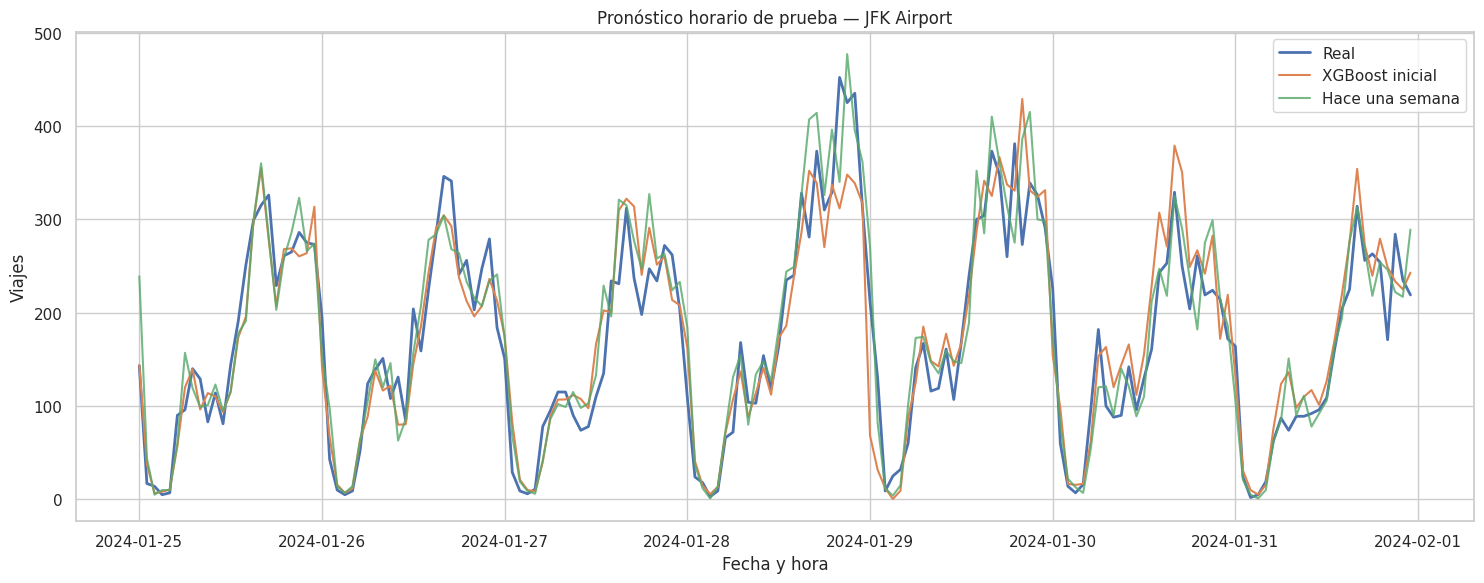

In [22]:
# ============================================================
# 21. COMPARACIÓN VISUAL EN LA ZONA DE MAYOR DEMANDA
# ============================================================

# Identificamos la zona con más viajes durante enero.
zona_ejemplo_id = int(
    zonas_pronostico.iloc[0]["PULocationID"]
)

zona_ejemplo_nombre = zonas_pronostico.iloc[0]["nombre_zona"]

# Filas de prueba de esa zona.
mascara = test["PULocationID"] == zona_ejemplo_id

grafico = test.loc[
    mascara,
    ["hora", "viajes", "lag_168"]
].copy()

# Añadimos las predicciones de XGBoost correspondientes.
grafico["pred_xgb"] = pred_xgb[mascara.to_numpy()]

plt.figure(figsize=(15, 6))

plt.plot(
    grafico["hora"],
    grafico["viajes"],
    label="Real",
    linewidth=2
)

plt.plot(
    grafico["hora"],
    grafico["pred_xgb"],
    label="XGBoost inicial"
)

plt.plot(
    grafico["hora"],
    grafico["lag_168"],
    label="Hace una semana",
    alpha=0.8
)

plt.title(
    f"Pronóstico horario de prueba — {zona_ejemplo_nombre}"
)
plt.xlabel("Fecha y hora")
plt.ylabel("Viajes")
plt.legend()
plt.tight_layout()
plt.show()


### Análisis

El modelo XGBoost reproduce la tendencia general de la demanda, pero en esta primera versión el baseline semanal obtiene mejores resultados: **MAE 11.88 frente a 13.07** y **RMSE 21.88 frente a 23.33**. Esto indica que la demanda tiene una fuerte repetición semanal y que el modelo definitivo deberá incorporar más información para superar esa referencia simple.


## 11. Interpretación parcial

Después de ejecutar el notebook se deben revisar principalmente:

1. El valor del **MAE** de XGBoost frente al baseline semanal.
2. El valor del **RMSE**, que penaliza más los errores grandes.
3. La gráfica de la zona de ejemplo para detectar horas donde el modelo falla.
4. Si la mejora es pequeña, esto no necesariamente significa que el modelo sea inútil. La demanda de taxis puede presentar una fuerte repetición semanal y una regla simple puede ser competitiva.

En la fase siguiente el objetivo será incorporar variables adicionales y convertir el pronóstico en un modelo **probabilístico por cuantiles**, de modo que la aplicación pueda mostrar un rango de incertidumbre y no únicamente una estimación puntual.


## 12. Preparación de datos para `/info`

La primera versión de la API todavía no necesita cargar el modelo para responder `/info`.

Se exportará un archivo con las zonas pronosticables y sus datos principales. FastAPI podrá utilizarlo para devolver:

- identificador de zona;
- nombre;
- distrito.

Posteriormente el endpoint también informará las fechas y los cuantiles disponibles.


In [23]:
# ============================================================
# 22. EXPORTAR INFORMACIÓN PARA LA API
# ============================================================

info_zonas = (
    zonas_pronostico[
        [
            "PULocationID",
            "nombre_zona",
            "distrito",
            "total_viajes"
        ]
    ]
    .sort_values("nombre_zona")
    .reset_index(drop=True)
)

RUTA_INFO_ZONAS = "info_zonas.csv"

info_zonas.to_csv(
    RUTA_INFO_ZONAS,
    index=False
)

print(f"✅ Archivo generado: {RUTA_INFO_ZONAS}")
print(f"Zonas exportadas: {len(info_zonas)}")

display(info_zonas.head())


✅ Archivo generado: info_zonas.csv
Zonas exportadas: 58


,PULocationID,nombre_zona,distrito,total_viajes
0,4,Alphabet City,Manhattan,3568
1,13,Battery Park City,Manhattan,15877
2,24,Bloomingdale,Manhattan,7849
3,41,Central Harlem,Manhattan,6832
4,42,Central Harlem North,Manhattan,3152


In [24]:
# ============================================================
# 23. EXPORTAR MÉTRICAS DEL MODELO INICIAL
# ============================================================

metricas_iniciales = pd.DataFrame({
    "modelo": [
        "baseline_semanal",
        "xgboost_inicial"
    ],
    "mae": [
        mae_baseline_mismo_test,
        mae_xgb
    ],
    "rmse": [
        rmse_baseline_mismo_test,
        rmse_xgb
    ]
})

metricas_iniciales.to_csv(
    "metricas_modelo_inicial.csv",
    index=False
)

print("✅ Archivo generado: metricas_modelo_inicial.csv")
display(metricas_iniciales.round(2))


✅ Archivo generado: metricas_modelo_inicial.csv


,modelo,mae,rmse
0,baseline_semanal,11.88,21.88
1,xgboost_inicial,13.07,23.33


# ✅ Resultado esperado de esta etapa

Al finalizar correctamente este notebook se debe contar con:

- una serie horaria completa con **744 horas por zona**;
- las zonas de pronóstico filtradas con el criterio de **3,000 viajes mínimos**;
- un baseline semanal basado en `lag_168`;
- un primer modelo XGBoost evaluado sobre el período **25–31 de enero**;
- una tabla comparativa de MAE y RMSE;
- una gráfica de ejemplo;
- `info_zonas.csv`, que se utilizará para construir la primera versión de `GET /info`;
- `metricas_modelo_inicial.csv`, útil para documentar el comportamiento del primer modelo.

---

## Próximo paso

Una vez comprobado que este notebook se ejecuta completo sin errores, el siguiente paso será crear:

```text
api/
├── main.py
├── info_zonas.csv
└── requirements.txt
```

y publicar una API mínima en Render que responda:

- `GET /`
- `GET /info`

Después se continuará con el modelo de cuantiles definitivo.


---

# 🗺️ Parte 2 — Segmentación de zonas con K-Means y PCA

## Objetivo

En esta segunda parte se busca identificar **tipos de zonas de taxi con comportamientos similares**.

A diferencia del pronóstico, aquí no se intenta predecir cuántos viajes habrá. El objetivo es responder una pregunta distinta:

> **¿Qué zonas se parecen entre sí por la forma en que son utilizadas?**

Para ello se utilizarán:

- **StandardScaler**, para colocar las variables en una escala comparable.
- **K-Means**, para agrupar zonas con perfiles similares.
- **Coeficiente de silueta**, para justificar el número de grupos.
- **PCA**, para representar visualmente las zonas en dos dimensiones.

La segmentación se realizará sobre las zonas que tengan al menos **500 viajes durante enero de 2024**.

### Variables utilizadas

Cada zona será resumida mediante:

- viajes promedio por día, en escala logarítmica;
- distancia mediana;
- tarifa mediana;
- propina mediana;
- porcentaje de viajes durante fines de semana;
- porcentaje de viajes de 6 a 10 h;
- porcentaje de viajes de 16 a 20 h;
- porcentaje de viajes de 22 a 5 h.

> Esta parte se calcula previamente en el notebook porque la segmentación no cambia cada vez que el usuario utiliza la app. Al final se exportará un CSV listo para Streamlit.


## 13. Importación de herramientas para segmentación

En la Parte 1 ya se importaron `pandas`, `numpy`, `matplotlib` y otras librerías.

Para esta sección únicamente se agregan las herramientas específicas de clustering:

- `StandardScaler`: estandarización de variables.
- `KMeans`: algoritmo de agrupamiento.
- `silhouette_score`: evaluación de la separación entre grupos.
- `PCA`: reducción de dimensionalidad para visualización.


In [25]:
# ============================================================
# 24. LIBRERÍAS PARA SEGMENTACIÓN
# ============================================================

# Herramienta para estandarizar variables antes de K-Means.
from sklearn.preprocessing import StandardScaler

# Algoritmo de agrupamiento no supervisado.
from sklearn.cluster import KMeans

# Métrica utilizada para justificar el número de clusters.
from sklearn.metrics import silhouette_score

# Reducción de dimensionalidad para representar los grupos en 2D.
from sklearn.decomposition import PCA

print("✅ Herramientas de segmentación importadas correctamente.")


✅ Herramientas de segmentación importadas correctamente.


## 14. Carga de variables necesarias para la segmentación

En la Parte 1 se cargaron únicamente la fecha del viaje y la zona de origen, porque eran suficientes para construir la serie horaria.

Para segmentar zonas se necesita información adicional:

- `trip_distance`: distancia recorrida;
- `fare_amount`: tarifa del viaje;
- `tip_amount`: propina;
- fecha y hora del viaje;
- zona de origen.

Se vuelve a leer el archivo Parquet seleccionando solo estas columnas. Esto mantiene un consumo de memoria razonable y evita cargar información que no se utilizará.


In [26]:
# ============================================================
# 25. CARGA DE DATOS PARA SEGMENTACIÓN
# ============================================================

columnas_segmentacion = [
    "tpep_pickup_datetime",
    "PULocationID",
    "trip_distance",
    "fare_amount",
    "tip_amount",
]

# Se leen únicamente las columnas necesarias para esta sección.
viajes_segmentacion = pd.read_parquet(
    URL_VIAJES,
    columns=columnas_segmentacion
)

print(
    f"Viajes cargados para segmentación: "
    f"{len(viajes_segmentacion):,}"
)


Viajes cargados para segmentación: 2,964,624


In [27]:
# ============================================================
# 26. LIMPIEZA TEMPORAL
# ============================================================

# Aseguramos que la fecha tenga formato datetime.
viajes_segmentacion["tpep_pickup_datetime"] = pd.to_datetime(
    viajes_segmentacion["tpep_pickup_datetime"],
    errors="coerce"
)

# Conservamos solo viajes cuyo inicio ocurrió durante enero de 2024.
viajes_segmentacion = viajes_segmentacion[
    (viajes_segmentacion["tpep_pickup_datetime"] >= FECHA_INICIO)
    &
    (viajes_segmentacion["tpep_pickup_datetime"] < FECHA_FIN_ENERO)
].copy()

print(
    f"Viajes válidos de enero para segmentación: "
    f"{len(viajes_segmentacion):,}"
)


Viajes válidos de enero para segmentación: 2,964,606


### Análisis de la limpieza temporal

Aplicar nuevamente el filtro de enero evita depender de supuestos sobre el archivo original.

Aunque el dataset se denomina `yellow_tripdata_2024-01`, la validación explícita de fechas garantiza que todas las estadísticas de segmentación correspondan al período definido por la actividad.


In [28]:
# ============================================================
# 27. INCORPORACIÓN DEL CATÁLOGO DE ZONAS
# ============================================================

# Relacionamos cada PULocationID con su nombre y distrito.
viajes_segmentacion = viajes_segmentacion.merge(
    catalogo,
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
)

viajes_segmentacion = viajes_segmentacion.rename(
    columns={
        "Zone": "nombre_zona",
        "Borough": "distrito",
    }
)

# Eliminamos zonas sin nombre y las denominadas "Unknown".
viajes_segmentacion = viajes_segmentacion[
    viajes_segmentacion["nombre_zona"].notna()
    &
    (
        viajes_segmentacion["nombre_zona"]
        .astype(str)
        .str.strip()
        .str.lower()
        != "unknown"
    )
].copy()

print(
    "Viajes después de eliminar zonas no identificadas:",
    f"{len(viajes_segmentacion):,}"
)


Viajes después de eliminar zonas no identificadas: 2,954,246


## 15. Selección de zonas para segmentación

El pronóstico y la segmentación utilizan reglas distintas:

- Pronóstico: zonas con **3,000 viajes o más**.
- Segmentación: zonas con **500 viajes o más**.

El límite menor permite analizar zonas menos concurridas sin incluir aquellas con tan pocos viajes que sus estadísticas mensuales resultarían poco representativas.


In [29]:
# ============================================================
# 28. SELECCIÓN DE ZONAS CON AL MENOS 500 VIAJES
# ============================================================

MIN_VIAJES_SEGMENTACION = 500

# Contamos los viajes por zona antes de aplicar filtros de
# distancia o tarifa, ya que el criterio de 500 viajes se basa
# en la actividad real de la zona.
conteo_segmentacion = (
    viajes_segmentacion
    .groupby("PULocationID")
    .size()
)

ids_segmentacion = conteo_segmentacion[
    conteo_segmentacion >= MIN_VIAJES_SEGMENTACION
].index

# Conservamos únicamente las zonas que cumplen el criterio.
viajes_segmentacion = viajes_segmentacion[
    viajes_segmentacion["PULocationID"].isin(ids_segmentacion)
].copy()

print(
    f"Zonas con al menos {MIN_VIAJES_SEGMENTACION} viajes:",
    len(ids_segmentacion)
)

print(
    f"Viajes utilizados para describir esas zonas:",
    f"{len(viajes_segmentacion):,}"
)


Zonas con al menos 500 viajes: 101
Viajes utilizados para describir esas zonas: 2,930,861


## 16. Construcción de variables de comportamiento

Las variables temporales permiten diferenciar zonas que pueden tener un volumen parecido de viajes, pero patrones de uso distintos.

Por ejemplo:

- una zona puede concentrar actividad durante la mañana;
- otra puede utilizarse principalmente en horario nocturno;
- otra puede aumentar su actividad los fines de semana.

Las variables se expresan como proporciones entre `0` y `1`. Posteriormente `StandardScaler` se encargará de hacerlas comparables con las variables monetarias y de distancia.


In [30]:
# ============================================================
# 29. VARIABLES TEMPORALES DE COMPORTAMIENTO
# ============================================================

# Hora del día: 0 a 23.
viajes_segmentacion["hora_dia"] = (
    viajes_segmentacion["tpep_pickup_datetime"].dt.hour
)

# Día de la semana: lunes=0, ..., domingo=6.
viajes_segmentacion["dia_semana"] = (
    viajes_segmentacion["tpep_pickup_datetime"].dt.dayofweek
)

# Fin de semana: sábado o domingo.
viajes_segmentacion["es_fin_semana"] = (
    viajes_segmentacion["dia_semana"] >= 5
).astype(int)

# Franja de mañana: 06:00 a 10:59.
viajes_segmentacion["es_manana"] = (
    viajes_segmentacion["hora_dia"].between(6, 10)
).astype(int)

# Franja de tarde: 16:00 a 20:59.
viajes_segmentacion["es_tarde"] = (
    viajes_segmentacion["hora_dia"].between(16, 20)
).astype(int)

# Franja nocturna: 22:00 a 05:59.
viajes_segmentacion["es_noche"] = (
    (viajes_segmentacion["hora_dia"] >= 22)
    |
    (viajes_segmentacion["hora_dia"] <= 5)
).astype(int)

display(
    viajes_segmentacion[
        [
            "PULocationID",
            "nombre_zona",
            "hora_dia",
            "dia_semana",
            "es_fin_semana",
            "es_manana",
            "es_tarde",
            "es_noche",
        ]
    ].head()
)


,PULocationID,nombre_zona,hora_dia,dia_semana,es_fin_semana,es_manana,es_tarde,es_noche
0,186,Penn Station/Madison Sq West,0,0,0,0,0,1
1,140,Lenox Hill East,0,0,0,0,0,1
2,236,Upper East Side North,0,0,0,0,0,1
3,79,East Village,0,0,0,0,0,1
4,211,SoHo,0,0,0,0,0,1


## 17. Creación de una fila por zona

K-Means necesita una matriz donde cada fila represente una observación.

En este caso:

> **una fila = una zona**

Para cada zona se calculan primero las variables de actividad y comportamiento utilizando todos sus viajes válidos.

Las medianas de **distancia** y **tarifa** se calculan por separado excluyendo únicamente valores menores o iguales a cero. Esto evita que registros físicamente imposibles o ajustes contables distorsionen el perfil.

La mediana se utiliza en lugar del promedio porque es menos sensible a viajes excepcionalmente largos o costosos.


In [31]:
# ============================================================
# 30. PERFIL GENERAL DE ACTIVIDAD POR ZONA
# ============================================================

# Estas variables se calculan con todos los viajes válidos
# de la zona, antes de filtrar distancia o tarifa.
perfil_actividad = (
    viajes_segmentacion
    .groupby(
        [
            "PULocationID",
            "nombre_zona",
            "distrito",
        ]
    )
    .agg(
        total_viajes=("PULocationID", "size"),
        pct_fin_semana=("es_fin_semana", "mean"),
        pct_manana=("es_manana", "mean"),
        pct_tarde=("es_tarde", "mean"),
        pct_noche=("es_noche", "mean"),
        propina_mediana=("tip_amount", "median"),
    )
    .reset_index()
)

# Distancia mediana: se descartan distancias <= 0.
distancia_mediana = (
    viajes_segmentacion[
        viajes_segmentacion["trip_distance"] > 0
    ]
    .groupby("PULocationID", as_index=False)["trip_distance"]
    .median()
    .rename(
        columns={"trip_distance": "distancia_mediana"}
    )
)

# Tarifa mediana: se descartan tarifas <= 0.
tarifa_mediana = (
    viajes_segmentacion[
        viajes_segmentacion["fare_amount"] > 0
    ]
    .groupby("PULocationID", as_index=False)["fare_amount"]
    .median()
    .rename(
        columns={"fare_amount": "tarifa_mediana"}
    )
)

# Unimos las estadísticas en una sola tabla por zona.
perfil_zonas = (
    perfil_actividad
    .merge(
        distancia_mediana,
        on="PULocationID",
        how="left"
    )
    .merge(
        tarifa_mediana,
        on="PULocationID",
        how="left"
    )
)

# Promedio de viajes diarios durante los 31 días de enero.
perfil_zonas["viajes_dia"] = (
    perfil_zonas["total_viajes"] / 31
)

# Escala logarítmica para reducir la diferencia entre
# zonas de baja y muy alta demanda.
perfil_zonas["log_viajes_dia"] = np.log1p(
    perfil_zonas["viajes_dia"]
)

display(perfil_zonas.head())


,PULocationID,nombre_zona,distrito,total_viajes,pct_fin_semana,pct_manana,pct_tarde,pct_noche,propina_mediana,distancia_mediana,tarifa_mediana,viajes_dia,log_viajes_dia
0,4,Alphabet City,Manhattan,3568,0.549327,0.135090,0.129204,0.591648,2.02,2.06,14.9,115.096774,4.754424
1,7,Astoria,Queens,1811,0.315295,0.286030,0.214246,0.205411,0.00,2.90,18.5,58.419355,4.084620
2,10,Baisley Park,Queens,999,0.229229,0.267267,0.277277,0.181181,0.00,14.10,70.0,32.225806,3.503327
3,12,Battery Park,Manhattan,875,0.262857,0.062857,0.289143,0.024000,2.66,4.60,24.7,28.225806,3.375052
4,13,Battery Park City,Manhattan,15877,0.174655,0.158342,0.428167,0.048057,3.57,3.50,19.8,512.161290,6.240590


In [32]:
# ============================================================
# 31. VERIFICACIÓN DEL PERFIL DE ZONAS
# ============================================================

print("Dimensiones del perfil:", perfil_zonas.shape)

print("\nValores faltantes:")
display(perfil_zonas.isna().sum())

# Las variables que utilizará K-Means deben estar completas.
columnas_perfil_requeridas = [
    "log_viajes_dia",
    "distancia_mediana",
    "tarifa_mediana",
    "propina_mediana",
    "pct_fin_semana",
    "pct_manana",
    "pct_tarde",
    "pct_noche",
]

# Si una zona no tiene información suficiente en alguna mediana,
# se elimina antes de entrenar K-Means.
perfil_zonas = perfil_zonas.dropna(
    subset=columnas_perfil_requeridas
).reset_index(drop=True)

print(
    "\nZonas disponibles después de validar variables:",
    len(perfil_zonas)
)

assert len(perfil_zonas) >= 2
assert perfil_zonas[columnas_perfil_requeridas].isna().sum().sum() == 0

print("✅ El perfil de zonas está listo para clustering.")


Dimensiones del perfil: (100, 13)

Valores faltantes:


,0
PULocationID,0
nombre_zona,0
distrito,0
total_viajes,0
pct_fin_semana,0
pct_manana,0
pct_tarde,0
pct_noche,0
propina_mediana,0
distancia_mediana,0



Zonas disponibles después de validar variables: 100
✅ El perfil de zonas está listo para clustering.


### Análisis del perfil por zona

La variable `viajes_dia` mide el nivel general de actividad de cada zona.

Sin embargo, se utilizará `log_viajes_dia` dentro de K-Means porque el número de viajes puede variar ampliamente entre zonas. La transformación logarítmica reduce esa asimetría sin eliminar la diferencia entre zonas de menor y mayor actividad.

Las variables temporales agregan información sobre **cuándo** se utiliza una zona, mientras que distancia, tarifa y propina ayudan a describir **qué tipo de viaje** se origina en ella.


## 18. Selección de variables y estandarización

Las variables de clustering están medidas en escalas diferentes.

Ejemplos:

- distancia: millas;
- tarifa: dólares;
- porcentajes: valores entre 0 y 1;
- viajes diarios: escala logarítmica.

K-Means utiliza distancias entre puntos. Si se entrenara directamente con estas escalas, una variable con valores numéricamente grandes podría dominar el resultado.

Por eso se aplica `StandardScaler`, que transforma cada variable para que tenga aproximadamente:

- media `0`;
- desviación estándar `1`.

De esta manera ninguna variable recibe más importancia únicamente por su unidad de medida.


In [33]:
# ============================================================
# 32. VARIABLES PARA K-MEANS Y ESCALAMIENTO
# ============================================================

VARIABLES_CLUSTER = [
    "log_viajes_dia",
    "distancia_mediana",
    "tarifa_mediana",
    "propina_mediana",
    "pct_fin_semana",
    "pct_manana",
    "pct_tarde",
    "pct_noche",
]

X_cluster = perfil_zonas[
    VARIABLES_CLUSTER
].copy()

# StandardScaler ajusta media y desviación a partir de los datos.
scaler_cluster = StandardScaler()

X_cluster_scaled = scaler_cluster.fit_transform(
    X_cluster
)

print("Dimensiones antes de escalar:", X_cluster.shape)
print("Dimensiones después de escalar:", X_cluster_scaled.shape)

# Verificación aproximada de la transformación.
print(
    "\nMedia promedio de variables escaladas:",
    f"{X_cluster_scaled.mean():.6f}"
)


Dimensiones antes de escalar: (100, 8)
Dimensiones después de escalar: (100, 8)

Media promedio de variables escaladas: -0.000000


## 19. Selección del número de grupos con coeficiente de silueta

No se fijará el número de clusters observando únicamente una gráfica ni copiando el resultado de un ejemplo.

Se evaluarán valores de:

\[
k = 2, 3, 4, 5, 6, 7
\]

Para cada valor se calcula el **coeficiente de silueta**.

Esta métrica combina dos ideas:

- **cohesión:** qué tan cerca está una zona de las demás zonas de su propio grupo;
- **separación:** qué tan lejos está de los otros grupos.

Entre las alternativas evaluadas se seleccionará el valor de `k` con mayor coeficiente de silueta.


In [34]:
# ============================================================
# 33. EVALUACIÓN DE K = 2 HASTA K = 7
# ============================================================

resultados_silueta = []

for k in range(2, 8):
    # n_init=20 prueba 20 inicializaciones distintas y conserva
    # la solución con menor inercia.
    modelo_kmeans = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=RANDOM_STATE,
    )

    etiquetas = modelo_kmeans.fit_predict(
        X_cluster_scaled
    )

    silueta = silhouette_score(
        X_cluster_scaled,
        etiquetas
    )

    resultados_silueta.append(
        {
            "k": k,
            "silueta": silueta,
        }
    )

tabla_silueta = pd.DataFrame(
    resultados_silueta
)

display(tabla_silueta.round(4))


,k,silueta
0,2,0.3443
1,3,0.3812
2,4,0.4113
3,5,0.3641
4,6,0.3886
5,7,0.3773


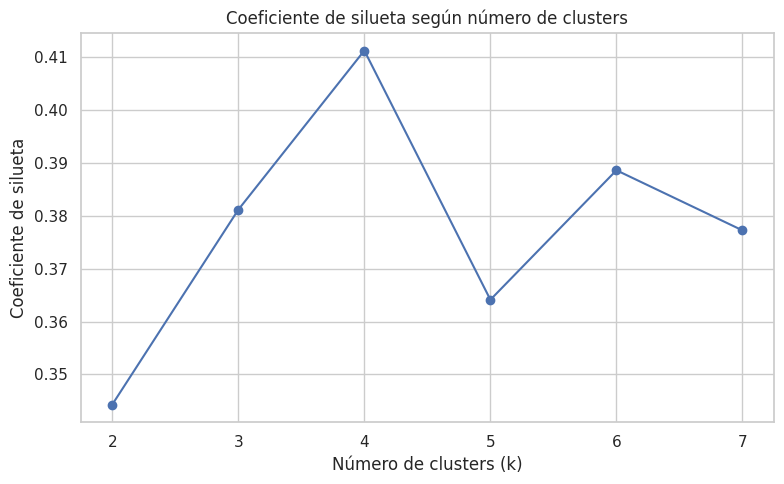

In [35]:
# ============================================================
# 34. GRÁFICA DEL COEFICIENTE DE SILUETA
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    tabla_silueta["k"],
    tabla_silueta["silueta"],
    marker="o",
)

plt.title(
    "Coeficiente de silueta según número de clusters"
)
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(range(2, 8))
plt.tight_layout()
plt.show()


### Análisis

El mayor coeficiente de silueta se obtiene con **k = 4**, alcanzando un valor de **0.4113**. Por esta razón se seleccionan cuatro clusters, ya que representan la mejor combinación entre cohesión interna y separación entre grupos dentro del rango evaluado de 2 a 7 clusters.


In [36]:
# ============================================================
# 35. SELECCIÓN AUTOMÁTICA DEL MEJOR K
# ============================================================

mejor_fila = tabla_silueta.loc[
    tabla_silueta["silueta"].idxmax()
]

MEJOR_K = int(
    mejor_fila["k"]
)

MEJOR_SILUETA = float(
    mejor_fila["silueta"]
)

print(
    f"Mejor número de clusters: k = {MEJOR_K}"
)

print(
    f"Coeficiente de silueta: {MEJOR_SILUETA:.4f}"
)

print(
    "\nAnálisis:"
)
print(
    "El valor seleccionado corresponde a la mejor combinación "
    "de cohesión interna y separación entre grupos dentro del "
    "rango k=2 a k=7."
)


Mejor número de clusters: k = 4
Coeficiente de silueta: 0.4113

Análisis:
El valor seleccionado corresponde a la mejor combinación de cohesión interna y separación entre grupos dentro del rango k=2 a k=7.


### Interpretación de la selección de `k`

El mejor valor de `k` se obtiene directamente de los datos.

Esto evita elegir el número de grupos porque “se ve mejor” o porque una versión de referencia utilizó cierta cantidad.

El coeficiente de silueta no convierte automáticamente una segmentación en perfecta, pero proporciona un criterio cuantitativo y reproducible para comparar las alternativas evaluadas.


## 20. Entrenamiento del K-Means definitivo

Una vez seleccionado `MEJOR_K`, se entrena nuevamente K-Means utilizando ese número de grupos.

Se mantiene:

```python
random_state = 42
```

para hacer reproducible la asignación obtenida.

También se conserva `n_init=20`, lo que reduce la dependencia de una única inicialización aleatoria de los centroides.


In [37]:
# ============================================================
# 36. K-MEANS DEFINITIVO
# ============================================================

kmeans_final = KMeans(
    n_clusters=MEJOR_K,
    n_init=20,
    random_state=RANDOM_STATE,
)

# fit_predict entrena el modelo y devuelve el grupo
# asignado a cada zona.
perfil_zonas["cluster"] = (
    kmeans_final.fit_predict(
        X_cluster_scaled
    )
)

print("Cantidad de zonas por cluster:")
display(
    perfil_zonas["cluster"]
    .value_counts()
    .sort_index()
    .rename("zonas")
    .to_frame()
)


Cantidad de zonas por cluster:


,zonas
cluster,
0,39
1,44
2,5
3,12


## 21. PCA para visualizar la segmentación

K-Means trabaja con ocho variables, por lo que sus grupos no pueden visualizarse directamente en un plano.

PCA transforma esas variables en nuevas componentes que concentran parte de la variación original.

Se utilizarán **dos componentes**:

- `PCA 1`
- `PCA 2`

PCA se utiliza aquí como herramienta de visualización. El clustering continúa basándose en las ocho variables escaladas, no únicamente en las dos componentes.


In [38]:
# ============================================================
# 37. REDUCCIÓN A DOS COMPONENTES CON PCA
# ============================================================

pca = PCA(
    n_components=2
)

componentes = pca.fit_transform(
    X_cluster_scaled
)

perfil_zonas["pca_1"] = componentes[:, 0]
perfil_zonas["pca_2"] = componentes[:, 1]

VARIACION_PCA_1 = pca.explained_variance_ratio_[0]
VARIACION_PCA_2 = pca.explained_variance_ratio_[1]
VARIACION_PCA_TOTAL = pca.explained_variance_ratio_.sum()

print(
    f"Variación explicada por PCA 1: "
    f"{VARIACION_PCA_1:.2%}"
)

print(
    f"Variación explicada por PCA 2: "
    f"{VARIACION_PCA_2:.2%}"
)

print(
    f"Variación total conservada en 2D: "
    f"{VARIACION_PCA_TOTAL:.2%}"
)


Variación explicada por PCA 1: 38.69%
Variación explicada por PCA 2: 27.07%
Variación total conservada en 2D: 65.75%


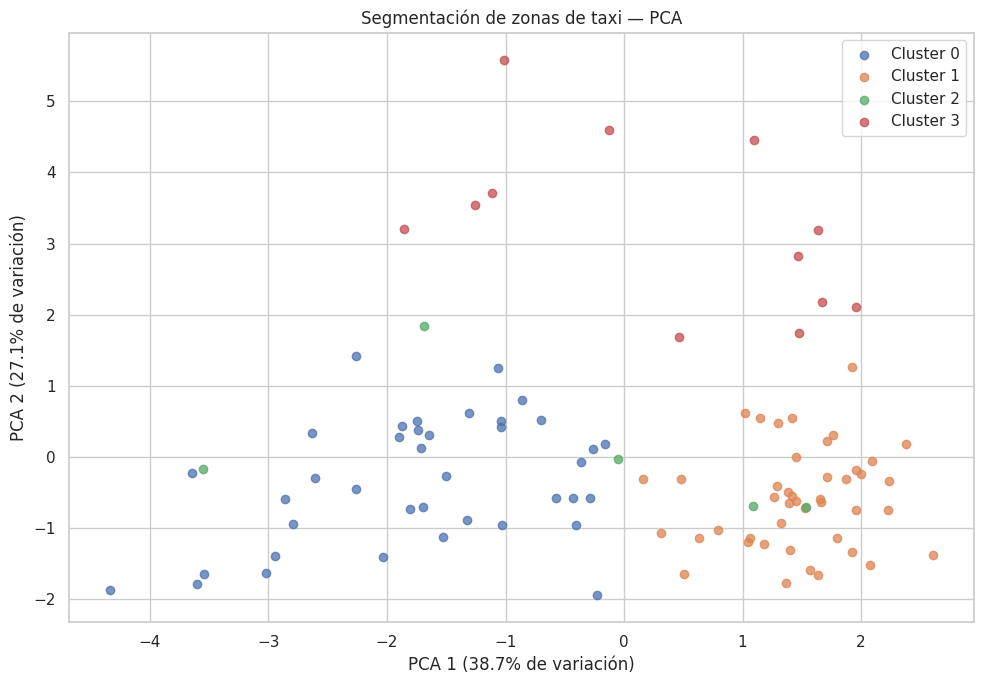

In [39]:
# ============================================================
# 38. VISUALIZACIÓN PCA DE LOS CLUSTERS
# ============================================================

plt.figure(figsize=(10, 7))

# Se dibuja cada cluster por separado para que aparezca
# correctamente identificado en la leyenda.
for cluster_id in sorted(
    perfil_zonas["cluster"].unique()
):
    datos_cluster = perfil_zonas[
        perfil_zonas["cluster"] == cluster_id
    ]

    plt.scatter(
        datos_cluster["pca_1"],
        datos_cluster["pca_2"],
        label=f"Cluster {cluster_id}",
        alpha=0.75,
    )

plt.title(
    "Segmentación de zonas de taxi — PCA"
)
plt.xlabel(
    f"PCA 1 ({VARIACION_PCA_1:.1%} de variación)"
)
plt.ylabel(
    f"PCA 2 ({VARIACION_PCA_2:.1%} de variación)"
)
plt.legend()
plt.tight_layout()
plt.show()


### Análisis

Las dos componentes principales conservan aproximadamente **65.75% de la variación total**, lo que permite visualizar razonablemente la estructura de los cuatro grupos. Se observa una separación clara en varios segmentos, especialmente en las zonas asociadas a viajes largos y tarifas elevadas, mientras que algunos grupos presentan cierto solapamiento, algo esperable al reducir ocho variables a solo dos dimensiones.


### Análisis de PCA

La gráfica PCA permite observar si los grupos definidos por K-Means presentan separación visual.

La suma de la variación explicada por `PCA 1` y `PCA 2` indica cuánta información de las ocho variables originales puede representarse en este plano.

Es importante recordar que:

- una visualización 2D siempre pierde parte de la información cuando la variación explicada es menor al 100%;
- dos puntos cercanos en PCA tienden a tener perfiles parecidos;
- los clusters fueron calculados con todas las variables escaladas, no con el gráfico.


## 22. Perfil de los clusters

Después de agrupar las zonas, el siguiente paso es interpretar **qué distingue a cada grupo**.

Para ello se calcula el promedio de las variables originales por cluster.

No se asignarán nombres únicamente según el número del cluster, porque K-Means puede cambiar las etiquetas numéricas entre ejecuciones o configuraciones.

Los nombres se construirán a partir de las características que más distinguen a cada grupo.


In [40]:
# ============================================================
# 39. PERFIL PROMEDIO DE CADA CLUSTER
# ============================================================

columnas_interpretacion = [
    "viajes_dia",
    "distancia_mediana",
    "tarifa_mediana",
    "propina_mediana",
    "pct_fin_semana",
    "pct_manana",
    "pct_tarde",
    "pct_noche",
]

perfil_clusters = (
    perfil_zonas
    .groupby("cluster")[
        columnas_interpretacion
    ]
    .mean()
)

display(
    perfil_clusters.round(3)
)


,viajes_dia,distancia_mediana,tarifa_mediana,propina_mediana,pct_fin_semana,pct_manana,pct_tarde,pct_noche
cluster,,,,,,,,
0,47.427,4.244,23.022,0.208,0.228,0.317,0.200,0.187
1,1732.278,1.915,13.330,2.665,0.248,0.176,0.331,0.135
2,1603.639,11.906,58.180,6.988,0.272,0.176,0.314,0.188
3,700.196,2.635,16.923,1.711,0.437,0.093,0.206,0.495


In [41]:
# ============================================================
# 40. NOMBRES Y DESCRIPCIONES BASADOS EN EL PERFIL
# ============================================================

# Para evitar nombres atados al número del cluster, comparamos
# los promedios de cada grupo entre sí mediante estandarización.
perfil_nombres = perfil_clusters.copy()

desviaciones = perfil_nombres.std(ddof=0).replace(0, 1)

perfil_clusters_std = (
    (perfil_nombres - perfil_nombres.mean())
    / desviaciones
)

etiquetas_variables = {
    "viajes_dia": "Alta demanda",
    "distancia_mediana": "Viajes de larga distancia",
    "tarifa_mediana": "Tarifas elevadas",
    "propina_mediana": "Mayor propina",
    "pct_fin_semana": "Actividad de fin de semana",
    "pct_manana": "Actividad matutina",
    "pct_tarde": "Actividad vespertina",
    "pct_noche": "Actividad nocturna",
}

nombres_clusters = {}
descripciones_clusters = {}

for cluster_id, fila in perfil_clusters_std.iterrows():
    # Tomamos las dos características que más destacan
    # positivamente frente a los demás grupos.
    principales = fila.sort_values(
        ascending=False
    ).index[:2].tolist()

    principal_1 = etiquetas_variables[
        principales[0]
    ]

    principal_2 = etiquetas_variables[
        principales[1]
    ]

    nombre = (
        f"{principal_1} · "
        f"{principal_2.lower()}"
    )

    descripcion = (
        f"Grupo caracterizado principalmente por "
        f"{principal_1.lower()} y "
        f"{principal_2.lower()} en comparación "
        f"con los demás segmentos."
    )

    nombres_clusters[cluster_id] = nombre
    descripciones_clusters[cluster_id] = descripcion

# Incorporamos los nombres a cada zona.
perfil_zonas["nombre_grupo"] = (
    perfil_zonas["cluster"]
    .map(nombres_clusters)
)

perfil_zonas["descripcion_grupo"] = (
    perfil_zonas["cluster"]
    .map(descripciones_clusters)
)

# Tabla resumen para revisar la interpretación.
resumen_clusters = pd.DataFrame(
    {
        "cluster": list(nombres_clusters.keys()),
        "nombre_grupo": list(nombres_clusters.values()),
        "descripcion": [
            descripciones_clusters[c]
            for c in nombres_clusters
        ],
    }
)

display(resumen_clusters)


,cluster,nombre_grupo,descripcion
0,0,Actividad matutina · viajes de larga distancia,Grupo caracterizado principalmente por activid...
1,1,Actividad vespertina · alta demanda,Grupo caracterizado principalmente por activid...
2,2,Tarifas elevadas · viajes de larga distancia,Grupo caracterizado principalmente por tarifas...
3,3,Actividad nocturna · actividad de fin de semana,Grupo caracterizado principalmente por activid...


### Análisis de los nombres de grupos

Los nombres anteriores se generan usando las características que más sobresalen en cada segmento frente a los demás.

Esto tiene dos ventajas:

1. El nombre depende del **perfil real del grupo**, no de que K-Means lo haya llamado `0`, `1`, `2`, etc.
2. Si cambia la numeración interna de K-Means, la interpretación sigue basándose en las características de los datos.

Antes de la entrega final conviene revisar también qué zonas específicas quedaron dentro de cada grupo. Si el conjunto de zonas permite un nombre más intuitivo —por ejemplo, un grupo dominado claramente por aeropuertos— el texto puede refinarse manteniendo siempre la justificación basada en el perfil.


In [42]:
# ============================================================
# 41. ZONAS REPRESENTATIVAS POR CLUSTER
# ============================================================

# Mostramos algunas zonas de cada grupo para apoyar
# la interpretación de los segmentos.
for cluster_id in sorted(
    perfil_zonas["cluster"].unique()
):
    nombre = nombres_clusters[cluster_id]

    print("\n" + "=" * 70)
    print(
        f"Cluster {cluster_id}: {nombre}"
    )

    muestra = (
        perfil_zonas[
            perfil_zonas["cluster"] == cluster_id
        ]
        .sort_values(
            "total_viajes",
            ascending=False
        )
        [
            [
                "nombre_zona",
                "distrito",
                "viajes_dia",
                "distancia_mediana",
                "tarifa_mediana",
            ]
        ]
        .head(8)
    )

    display(muestra.round(2))



Cluster 0: Actividad matutina · viajes de larga distancia


,nombre_zona,distrito,viajes_dia,distancia_mediana,tarifa_mediana
12,Central Harlem,Manhattan,220.39,1.64,12.10
25,East Harlem North,Manhattan,198.19,1.77,12.80
78,Stuy Town/Peter Cooper Village,Manhattan,119.48,1.84,13.50
13,Central Harlem North,Manhattan,101.68,2.28,17.50
55,Long Island City/Hunters Point,Queens,89.16,3.20,12.18
80,Sunnyside,Queens,83.81,3.57,21.20
43,Hamilton Heights,Manhattan,70.90,2.90,18.50
72,Queensbridge/Ravenswood,Queens,70.45,3.31,3.00



Cluster 1: Actividad vespertina · alta demanda


,nombre_zona,distrito,viajes_dia,distancia_mediana,tarifa_mediana
61,Midtown Center,Manhattan,4628.03,1.53,12.1
88,Upper East Side South,Manhattan,4603.45,1.23,10.0
87,Upper East Side North,Manhattan,4402.06,1.40,10.7
62,Midtown East,Manhattan,3442.48,1.51,12.1
82,Times Sq/Theatre District,Manhattan,3429.81,1.60,12.8
70,Penn Station/Madison Sq West,Manhattan,3371.68,1.54,13.5
52,Lincoln Square East,Manhattan,3357.42,1.60,11.4
90,Upper West Side South,Manhattan,2854.00,1.60,11.4



Cluster 2: Tarifas elevadas · viajes de larga distancia


,nombre_zona,distrito,viajes_dia,distancia_mediana,tarifa_mediana
47,JFK Airport,Queens,4685.16,17.41,70.0
49,LaGuardia Airport,Queens,2888.06,9.48,40.8
24,East Elmhurst,Queens,396.29,9.33,40.1
2,Baisley Park,Queens,32.23,14.10,70.0
35,Flushing Meadows-Corona Park,Queens,16.45,9.21,70.0



Cluster 3: Actividad nocturna · actividad de fin de semana


,nombre_zona,distrito,viajes_dia,distancia_mediana,tarifa_mediana
93,West Village,Manhattan,2136.35,1.61,12.1
28,East Village,Manhattan,2126.94,1.69,12.1
42,Greenwich Village South,Manhattan,1301.42,1.68,12.1
57,Lower East Side,Manhattan,902.06,2.10,14.2
54,Little Italy/NoLiTa,Manhattan,826.35,1.90,13.5
60,Meatpacking/West Village West,Manhattan,765.23,1.84,13.5
84,Two Bridges/Seward Park,Manhattan,120.55,2.86,17.7
0,Alphabet City,Manhattan,115.10,2.06,14.9


## 23. Perfil horario de cada zona

Además del cluster, la aplicación de Streamlit mostrará cómo se distribuyen los viajes a lo largo de las 24 horas.

Para cada zona se calcula:

\[
\text{proporción horaria}
=
\frac{\text{viajes de esa hora}}
{\text{viajes totales de la zona}}
\]

El resultado se exportará en formato largo, con una fila por zona y hora. Streamlit podrá utilizarlo para construir mini gráficos o perfiles horarios interactivos.


In [43]:
# ============================================================
# 42. PERFIL HORARIO PARA STREAMLIT
# ============================================================

perfil_horario = (
    viajes_segmentacion
    .groupby(
        [
            "PULocationID",
            "hora_dia",
        ]
    )
    .size()
    .reset_index(name="viajes")
)

# Proporción de viajes de cada hora dentro de la zona.
perfil_horario["proporcion"] = (
    perfil_horario["viajes"]
    /
    perfil_horario
    .groupby("PULocationID")["viajes"]
    .transform("sum")
)

perfil_horario = perfil_horario.rename(
    columns={
        "PULocationID": "zona_id",
        "hora_dia": "hora",
    }
)

display(perfil_horario.head())


,zona_id,hora,viajes,proporcion
0,4,0,391,0.109585
1,4,1,540,0.151345
2,4,2,446,0.125000
3,4,3,242,0.067825
4,4,4,72,0.020179


## 24. Exportación para la aplicación

La aplicación de Streamlit **no volverá a entrenar K-Means en cada clic**.

El notebook deja calculados todos los resultados y exporta archivos ligeros:

- `zonas_segmentadas.csv`: una fila por zona, con variables, cluster, nombre del grupo y coordenadas PCA.
- `perfiles_horarios.csv`: distribución de viajes por hora de cada zona.
- `silueta_k.csv`: resultados usados para justificar `k`.
- `resumen_clusters.csv`: nombre y descripción de cada grupo.

Estos archivos se copiarán posteriormente a:

```text
app/data/
```

De esta manera la app se limita a leer y visualizar resultados ya calculados.


In [44]:
# ============================================================
# 43. PREPARACIÓN DEL CSV PRINCIPAL DE SEGMENTACIÓN
# ============================================================

zonas_segmentadas = perfil_zonas.copy()

# Nombres más cómodos para Streamlit.
zonas_segmentadas = zonas_segmentadas.rename(
    columns={
        "PULocationID": "zona_id",
        "nombre_zona": "zona",
    }
)

columnas_exportacion = [
    "zona_id",
    "zona",
    "distrito",
    "total_viajes",
    "viajes_dia",
    "log_viajes_dia",
    "distancia_mediana",
    "tarifa_mediana",
    "propina_mediana",
    "pct_fin_semana",
    "pct_manana",
    "pct_tarde",
    "pct_noche",
    "cluster",
    "nombre_grupo",
    "descripcion_grupo",
    "pca_1",
    "pca_2",
]

zonas_segmentadas = zonas_segmentadas[
    columnas_exportacion
].copy()

display(zonas_segmentadas.head())


,zona_id,zona,distrito,total_viajes,viajes_dia,log_viajes_dia,distancia_mediana,tarifa_mediana,propina_mediana,pct_fin_semana,pct_manana,pct_tarde,pct_noche,cluster,nombre_grupo,descripcion_grupo,pca_1,pca_2
0,4,Alphabet City,Manhattan,3568,115.096774,4.754424,2.06,14.9,2.02,0.549327,0.135090,0.129204,0.591648,3,Actividad nocturna · actividad de fin de semana,Grupo caracterizado principalmente por activid...,-0.124946,4.597964
1,7,Astoria,Queens,1811,58.419355,4.084620,2.90,18.5,0.00,0.315295,0.286030,0.214246,0.205411,0,Actividad matutina · viajes de larga distancia,Grupo caracterizado principalmente por activid...,-1.039681,0.415141
2,10,Baisley Park,Queens,999,32.225806,3.503327,14.10,70.0,0.00,0.229229,0.267267,0.277277,0.181181,2,Tarifas elevadas · viajes de larga distancia,Grupo caracterizado principalmente por tarifas...,-3.549715,-0.169602
3,12,Battery Park,Manhattan,875,28.225806,3.375052,4.60,24.7,2.66,0.262857,0.062857,0.289143,0.024000,1,Actividad vespertina · alta demanda,Grupo caracterizado principalmente por activid...,0.163067,-0.310956
4,13,Battery Park City,Manhattan,15877,512.161290,6.240590,3.50,19.8,3.57,0.174655,0.158342,0.428167,0.048057,1,Actividad vespertina · alta demanda,Grupo caracterizado principalmente por activid...,1.638222,-1.664240


In [45]:
# ============================================================
# 44. EXPORTACIÓN DE ARCHIVOS PARA STREAMLIT
# ============================================================

zonas_segmentadas.to_csv(
    "zonas_segmentadas.csv",
    index=False,
)

perfil_horario.to_csv(
    "perfiles_horarios.csv",
    index=False,
)

tabla_silueta.to_csv(
    "silueta_k.csv",
    index=False,
)

resumen_clusters.to_csv(
    "resumen_clusters.csv",
    index=False,
)

print("✅ Archivos generados:")
print("   - zonas_segmentadas.csv")
print("   - perfiles_horarios.csv")
print("   - silueta_k.csv")
print("   - resumen_clusters.csv")


✅ Archivos generados:
   - zonas_segmentadas.csv
   - perfiles_horarios.csv
   - silueta_k.csv
   - resumen_clusters.csv


In [46]:
# ============================================================
# 45. VERIFICACIÓN FINAL DE LA SEGMENTACIÓN
# ============================================================

# Debe existir una fila por cada zona segmentada.
assert zonas_segmentadas["zona_id"].is_unique

# Ninguna zona puede quedar sin grupo.
assert zonas_segmentadas["cluster"].isna().sum() == 0

# Deben existir exactamente MEJOR_K grupos.
assert zonas_segmentadas["cluster"].nunique() == MEJOR_K

# Las coordenadas PCA deben estar completas.
assert zonas_segmentadas[
    ["pca_1", "pca_2"]
].isna().sum().sum() == 0

# El perfil horario debe contener horas entre 0 y 23.
assert perfil_horario["hora"].between(0, 23).all()

print("✅ Verificaciones completadas correctamente.")
print(
    f"Zonas segmentadas: {len(zonas_segmentadas)}"
)
print(
    f"Número de grupos: {MEJOR_K}"
)
print(
    f"Silueta seleccionada: {MEJOR_SILUETA:.4f}"
)
print(
    f"Variación PCA en 2 dimensiones: "
    f"{VARIACION_PCA_TOTAL:.2%}"
)


✅ Verificaciones completadas correctamente.
Zonas segmentadas: 100
Número de grupos: 4
Silueta seleccionada: 0.4113
Variación PCA en 2 dimensiones: 65.75%


# 📌 Conclusiones parciales — Partes 1 y 2

## Parte 1 — Serie horaria y primer pronóstico

La primera etapa transformó millones de viajes individuales en una serie temporal estructurada por zona y hora.

El uso de una división temporal —en lugar de `train_test_split`— mantiene la lógica real del problema: el modelo aprende del pasado y se evalúa sobre fechas posteriores.

El baseline `lag_168` representa una referencia fuerte y fácil de explicar: asumir que la demanda será igual a la observada exactamente una semana antes.

El primer XGBoost permite comprobar que la tubería de entrenamiento, predicción y evaluación funciona correctamente. Sus métricas deben interpretarse siempre frente al baseline y no de forma aislada.

## Parte 2 — Segmentación de zonas

La segunda etapa cambia el enfoque de supervisado a no supervisado.

K-Means agrupa zonas según su nivel de actividad, características típicas del viaje y distribución temporal. Antes de entrenarlo se utiliza `StandardScaler`, evitando que una variable domine el clustering únicamente por tener una escala numérica mayor.

El número de clusters se selecciona mediante el coeficiente de silueta evaluado entre `k=2` y `k=7`, haciendo que la decisión esté sustentada en los datos.

PCA permite visualizar los grupos en dos dimensiones e informa qué proporción de la variación original se conserva en esa representación.

Finalmente, los resultados de la segmentación quedan precalculados en archivos CSV. Esto permite que Streamlit se concentre en la interacción y visualización, sin recalcular el modelo cada vez que el usuario utiliza la aplicación.

---

## Archivos que deja preparado este notebook

### Para la API mínima

- `info_zonas.csv`
- `metricas_modelo_inicial.csv`

### Para la página de segmentación en Streamlit

- `zonas_segmentadas.csv`
- `perfiles_horarios.csv`
- `silueta_k.csv`
- `resumen_clusters.csv`

El siguiente paso del proyecto será construir la carpeta `app/`, crear la página de **Segmentación de zonas** y publicarla en **Streamlit Community Cloud**.


# 🔮 Parte 3 — Modelo final de series de tiempo por cuantiles

En esta etapa se construye el modelo definitivo de pronóstico que utilizará la API.

La metodología sigue los mismos principios trabajados en la clase de series de tiempo:

- el futuro se evalúa respetando el orden temporal;
- se utiliza una regla simple como referencia;
- solo se incluyen variables que estarían disponibles al momento de pronosticar;
- no se utilizan rezagos menores a 24 horas;
- el modelo entrega varios cuantiles para representar la incertidumbre.

El objetivo ya no es obtener únicamente un valor central, sino un rango de posibles valores que posteriormente permitirá tomar decisiones según el costo de enviar taxis de más o de menos.


## 25. Preparación de la serie para el modelo final

La API debe poder responder tanto para la semana de prueba como para el **1 de febrero de 2024**.

Por ello se agregan las 24 horas del 1 de febrero antes de calcular los rezagos. Estas filas no tienen un valor real de demanda, pero sí pueden obtener información histórica de enero.


In [47]:
# ============================================================
# 46. AGREGAR LAS HORAS DEL 1 DE FEBRERO
# ============================================================

# Creamos las 24 horas que representan el pronóstico futuro.
horas_futuro = pd.date_range(
    start="2024-02-01 00:00:00",
    end="2024-02-01 23:00:00",
    freq="h",
)

# Combinamos cada zona pronosticable con las 24 horas futuras.
indice_futuro = pd.MultiIndex.from_product(
    [ids_zonas, horas_futuro],
    names=["PULocationID", "hora"],
)

futuro = indice_futuro.to_frame(index=False)

# El 1 de febrero no tiene un valor real conocido.
futuro["viajes"] = np.nan

# Conservamos únicamente las columnas base y agregamos el futuro.
demanda_final = pd.concat(
    [
        demanda[["PULocationID", "hora", "viajes"]].copy(),
        futuro,
    ],
    ignore_index=True,
)

demanda_final = demanda_final.sort_values(
    ["PULocationID", "hora"]
).reset_index(drop=True)

print(
    "Período disponible:",
    demanda_final["hora"].min(),
    "→",
    demanda_final["hora"].max(),
)
print("Filas totales:", f"{len(demanda_final):,}")


Período disponible: 2024-01-01 00:00:00 → 2024-02-01 23:00:00
Filas totales: 44,544


## 26. Variables temporales definitivas

Se agregan rezagos diarios y semanales. Los rezagos `167`, `168` y `169` permiten observar el comportamiento alrededor de la misma hora de la semana anterior.

También se incorpora el promedio horario del día anterior y variables de calendario. La zona se conserva como variable categórica nativa de XGBoost.


In [48]:
# ============================================================
# 47. CREACIÓN DE LOS REZAGOS DEFINITIVOS
# ============================================================

grupo_zona = demanda_final.groupby(
    "PULocationID"
)["viajes"]

# Información de ayer y anteayer.
demanda_final["lag_24"] = grupo_zona.shift(24)
demanda_final["lag_48"] = grupo_zona.shift(48)

# Información alrededor de la misma hora de la semana anterior.
demanda_final["lag_167"] = grupo_zona.shift(167)
demanda_final["lag_168"] = grupo_zona.shift(168)
demanda_final["lag_169"] = grupo_zona.shift(169)

display(
    demanda_final[
        [
            "PULocationID",
            "hora",
            "viajes",
            "lag_24",
            "lag_48",
            "lag_167",
            "lag_168",
            "lag_169",
        ]
    ].tail(30)
)


,PULocationID,hora,viajes,lag_24,lag_48,lag_167,lag_168,lag_169
44514,263,2024-01-31 18:00:00,132.0,107.0,124.0,102.0,119.0,103.0
44515,263,2024-01-31 19:00:00,106.0,115.0,92.0,98.0,102.0,119.0
44516,263,2024-01-31 20:00:00,104.0,99.0,87.0,95.0,98.0,102.0
44517,263,2024-01-31 21:00:00,92.0,96.0,62.0,73.0,95.0,98.0
44518,263,2024-01-31 22:00:00,80.0,63.0,48.0,44.0,73.0,95.0
44519,263,2024-01-31 23:00:00,53.0,42.0,29.0,18.0,44.0,73.0
44520,263,2024-02-01 00:00:00,NaN,13.0,10.0,15.0,18.0,44.0
44521,263,2024-02-01 01:00:00,NaN,8.0,12.0,3.0,15.0,18.0
44522,263,2024-02-01 02:00:00,NaN,3.0,8.0,3.0,3.0,15.0
44523,263,2024-02-01 03:00:00,NaN,2.0,4.0,8.0,3.0,3.0


In [49]:
# ============================================================
# 48. PROMEDIO DEL DÍA ANTERIOR
# ============================================================

# Calculamos el promedio de viajes por hora para cada zona y día.
medias_diarias = (
    demanda_final
    .dropna(subset=["viajes"])
    .assign(fecha=lambda df: df["hora"].dt.normalize())
    .groupby(["PULocationID", "fecha"], as_index=False)["viajes"]
    .mean()
    .rename(columns={"viajes": "media_dia_ant"})
)

# Desplazamos la fecha un día hacia adelante.
# De esta manera, el promedio del 31 de enero queda asociado
# con las filas correspondientes al 1 de febrero.
medias_diarias["fecha"] = (
    medias_diarias["fecha"] + pd.Timedelta(days=1)
)

demanda_final["fecha"] = (
    demanda_final["hora"].dt.normalize()
)

demanda_final = demanda_final.merge(
    medias_diarias,
    on=["PULocationID", "fecha"],
    how="left",
)

display(
    demanda_final[
        [
            "PULocationID",
            "hora",
            "viajes",
            "media_dia_ant",
        ]
    ].tail(30)
)


,PULocationID,hora,viajes,media_dia_ant
44514,263,2024-01-31 18:00:00,132.0,80.041667
44515,263,2024-01-31 19:00:00,106.0,80.041667
44516,263,2024-01-31 20:00:00,104.0,80.041667
44517,263,2024-01-31 21:00:00,92.0,80.041667
44518,263,2024-01-31 22:00:00,80.0,80.041667
44519,263,2024-01-31 23:00:00,53.0,80.041667
44520,263,2024-02-01 00:00:00,NaN,80.833333
44521,263,2024-02-01 01:00:00,NaN,80.833333
44522,263,2024-02-01 02:00:00,NaN,80.833333
44523,263,2024-02-01 03:00:00,NaN,80.833333


### Nota sobre los valores `NaN`

Los `NaN` de la columna `viajes` correspondientes al **1 de febrero** son intencionales. Ese día representa el período futuro que se desea pronosticar, por lo que todavía no existe una demanda real observada. Las variables históricas utilizadas por el modelo, como los rezagos y el promedio del día anterior, sí se encuentran disponibles.


In [50]:
# ============================================================
# 49. VARIABLES DE CALENDARIO Y ZONA
# ============================================================

demanda_final["hora_dia"] = (
    demanda_final["hora"].dt.hour
)

demanda_final["dia_semana"] = (
    demanda_final["hora"].dt.dayofweek
)

# Martin Luther King Jr. Day.
demanda_final["feriado"] = (
    demanda_final["hora"].dt.normalize()
    == pd.Timestamp("2024-01-15")
).astype(int)

# La zona se utiliza como categoría nativa de XGBoost.
categorias_zonas = sorted(
    int(zona) for zona in ids_zonas
)

demanda_final["zona"] = pd.Categorical(
    demanda_final["PULocationID"],
    categories=categorias_zonas,
)

VARIABLES_FINALES = [
    "lag_24",
    "lag_48",
    "lag_167",
    "lag_168",
    "lag_169",
    "media_dia_ant",
    "hora_dia",
    "dia_semana",
    "feriado",
    "zona",
]

print("Variables del modelo final:")
for variable in VARIABLES_FINALES:
    print(" -", variable)


Variables del modelo final:
 - lag_24
 - lag_48
 - lag_167
 - lag_168
 - lag_169
 - media_dia_ant
 - hora_dia
 - dia_semana
 - feriado
 - zona


### Por qué no se utiliza `lag_1`

El pronóstico se prepara para las 24 horas del día siguiente. Al momento de realizarlo todavía no se conocen los viajes de las horas anteriores de ese mismo día futuro.

Por esa razón, utilizar `lag_1` produciría fuga de información y daría una evaluación artificialmente buena.


## 27. División temporal final

Se mantiene exactamente la división solicitada:

- **Entrenamiento:** hasta el 24 de enero.
- **Prueba:** del 25 al 31 de enero.
- **Futuro:** 1 de febrero.

No se utiliza `train_test_split`, porque mezclar observaciones del futuro con el pasado produciría una evaluación incorrecta para una serie de tiempo.


In [51]:
# ============================================================
# 50. PREPARACIÓN DE TRAIN, TEST Y FUTURO
# ============================================================

# Solo eliminamos filas que todavía no tienen suficiente historia
# para construir todas las variables del modelo.
datos_finales = demanda_final.dropna(
    subset=VARIABLES_FINALES
).copy()

train_final = datos_finales[
    datos_finales["hora"] < pd.Timestamp("2024-01-25")
].copy()

test_final = datos_finales[
    (datos_finales["hora"] >= pd.Timestamp("2024-01-25"))
    & (datos_finales["hora"] < pd.Timestamp("2024-02-01"))
].copy()

futuro_final = datos_finales[
    (datos_finales["hora"] >= pd.Timestamp("2024-02-01"))
    & (datos_finales["hora"] < pd.Timestamp("2024-02-02"))
].copy()

X_train_final = train_final[VARIABLES_FINALES]
y_train_final = train_final["viajes"]

X_test_final = test_final[VARIABLES_FINALES]
y_test_final = test_final["viajes"]

X_futuro_final = futuro_final[VARIABLES_FINALES]

print(f"Entrenamiento: {len(train_final):,} filas")
print(f"Prueba:        {len(test_final):,} filas")
print(f"Futuro:        {len(futuro_final):,} filas")

print("\nEntrenamiento:")
print(train_final["hora"].min(), "→", train_final["hora"].max())

print("\nPrueba:")
print(test_final["hora"].min(), "→", test_final["hora"].max())

print("\nFuturo:")
print(futuro_final["hora"].min(), "→", futuro_final["hora"].max())


Entrenamiento: 23,606 filas
Prueba:        9,744 filas
Futuro:        1,392 filas

Entrenamiento:
2024-01-08 01:00:00 → 2024-01-24 23:00:00

Prueba:
2024-01-25 00:00:00 → 2024-01-31 23:00:00

Futuro:
2024-02-01 00:00:00 → 2024-02-01 23:00:00


## 28. Modelo XGBoost por cuantiles

El modelo utiliza `objective="reg:quantileerror"` para producir varios cuantiles en una sola predicción.

Se utilizan los cuantiles del **10% al 90%**, avanzando de 10 en 10. Esto permite:

- representar un intervalo de incertidumbre;
- utilizar `p50` como pronóstico central;
- elegir posteriormente un cuantil según el costo operativo de equivocarse.

Los parámetros mantienen una complejidad moderada para evitar un modelo innecesariamente grande al publicarlo en Render.


In [52]:
# ============================================================
# 51. DEFINICIÓN DE LOS CUANTILES
# ============================================================

CUANTILES = np.arange(
    0.1,
    1.0,
    0.1,
).round(1)

NOMBRES_CUANTILES = [
    f"p{int(q * 100)}"
    for q in CUANTILES
]

print("Cuantiles:", CUANTILES)
print("Nombres:", NOMBRES_CUANTILES)


Cuantiles: [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]
Nombres: ['p10', 'p20', 'p30', 'p40', 'p50', 'p60', 'p70', 'p80', 'p90']


In [53]:
# ============================================================
# 52. ENTRENAMIENTO DEL MODELO FINAL POR CUANTILES
# ============================================================

modelo_cuantiles = XGBRegressor(
    objective="reg:quantileerror",
    quantile_alpha=CUANTILES,
    enable_categorical=True,
    tree_method="hist",
    n_estimators=250,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

modelo_cuantiles.fit(
    X_train_final,
    y_train_final,
)

print("✅ Modelo final por cuantiles entrenado correctamente.")


✅ Modelo final por cuantiles entrenado correctamente.


## 29. Evaluación del pronóstico central

Para comparar el modelo con la regla simple se utiliza `p50`, que representa la mediana del pronóstico.

La comparación se realiza sobre exactamente las mismas filas de la semana de prueba.


In [54]:
# ============================================================
# 53. PREDICCIÓN Y ORDENAMIENTO DE CUANTILES
# ============================================================

pred_cuantiles = modelo_cuantiles.predict(
    X_test_final
)

# XGBoost puede producir cuantiles cruzados en algunas filas.
# Los ordenamos para garantizar p10 <= p20 <= ... <= p90.
pred_cuantiles = np.sort(
    pred_cuantiles,
    axis=1,
)

# La demanda no puede ser negativa.
pred_cuantiles = np.maximum(
    pred_cuantiles,
    0,
)

predicciones_test = pd.DataFrame(
    pred_cuantiles,
    columns=NOMBRES_CUANTILES,
    index=test_final.index,
)

predicciones_test["real"] = (
    y_test_final
)

predicciones_test["hace_una_semana"] = (
    test_final["lag_168"]
)

display(
    predicciones_test.head()
)


,p10,p20,p30,p40,p50,p60,p70,p80,p90,real,hace_una_semana
576,0.083996,0.820912,1.246627,1.386167,1.967504,2.692842,3.242153,5.181286,17.944532,4.0,2.0
577,0.000000,0.018599,0.022812,0.463003,0.932719,1.180637,1.826829,3.412848,17.053497,2.0,1.0
578,0.000000,0.000000,0.051453,0.131747,0.399077,0.889481,1.385580,2.991165,16.899847,0.0,0.0
579,0.000000,0.000000,0.000000,0.007794,0.371970,0.820732,1.296644,2.892706,16.899847,0.0,0.0
580,0.000000,0.000000,0.000000,0.007794,0.371970,0.820732,1.296644,2.892706,16.899847,0.0,0.0


In [55]:
# ============================================================
# 54. MÉTRICAS DEL MODELO FINAL
# ============================================================

pred_p50 = predicciones_test["p50"]

mae_final = mean_absolute_error(
    y_test_final,
    pred_p50,
)

rmse_final = np.sqrt(
    mean_squared_error(
        y_test_final,
        pred_p50,
    )
)

mae_baseline_final = mean_absolute_error(
    y_test_final,
    predicciones_test["hace_una_semana"],
)

rmse_baseline_final = np.sqrt(
    mean_squared_error(
        y_test_final,
        predicciones_test["hace_una_semana"],
    )
)

comparacion_final = pd.DataFrame({
    "Modelo": [
        "Igual que hace una semana",
        "XGBoost final p50",
    ],
    "MAE": [
        mae_baseline_final,
        mae_final,
    ],
    "RMSE": [
        rmse_baseline_final,
        rmse_final,
    ],
})

display(
    comparacion_final.round(2)
)


,Modelo,MAE,RMSE
0,Igual que hace una semana,11.88,21.88
1,XGBoost final p50,11.89,22.45


### Análisis

El modelo final y la regla semanal obtienen resultados prácticamente iguales en MAE: **11.89 frente a 11.88**. En RMSE, la regla semanal también presenta un resultado ligeramente mejor (**21.88 frente a 22.45**). Esto confirma que la demanda tiene una fuerte repetición semanal; el valor adicional del modelo final está principalmente en los cuantiles y en la representación de la incertidumbre.


## 30. Cobertura del intervalo de incertidumbre

El rango entre `p10` y `p90` representa un intervalo nominal del **80%**.

Además del error del pronóstico central, es importante medir cuántos valores reales quedan efectivamente dentro de este intervalo.


In [56]:
# ============================================================
# 55. COBERTURA DEL INTERVALO P10 - P90
# ============================================================

dentro_intervalo = (
    (predicciones_test["real"] >= predicciones_test["p10"])
    & (predicciones_test["real"] <= predicciones_test["p90"])
)

cobertura_80 = dentro_intervalo.mean()

ancho_medio_intervalo = (
    predicciones_test["p90"]
    - predicciones_test["p10"]
).mean()

print(
    f"Cobertura observada p10-p90: "
    f"{cobertura_80:.2%}"
)

print(
    f"Ancho medio del intervalo: "
    f"{ancho_medio_intervalo:.2f} viajes"
)


Cobertura observada p10-p90: 89.98%
Ancho medio del intervalo: 49.61 viajes


### Análisis

El intervalo `p10–p90` alcanza una cobertura observada de **89.98%**, superior al 80% nominal. Esto indica que el rango contiene la mayoría de los valores reales, aunque también resulta algo conservador, con un ancho medio de aproximadamente **49.61 viajes**.


## 31. Visualización del modelo final

Se muestra una zona representativa para comparar:

- demanda real;
- pronóstico central `p50`;
- regla de hace una semana;
- intervalo de incertidumbre `p10–p90`.


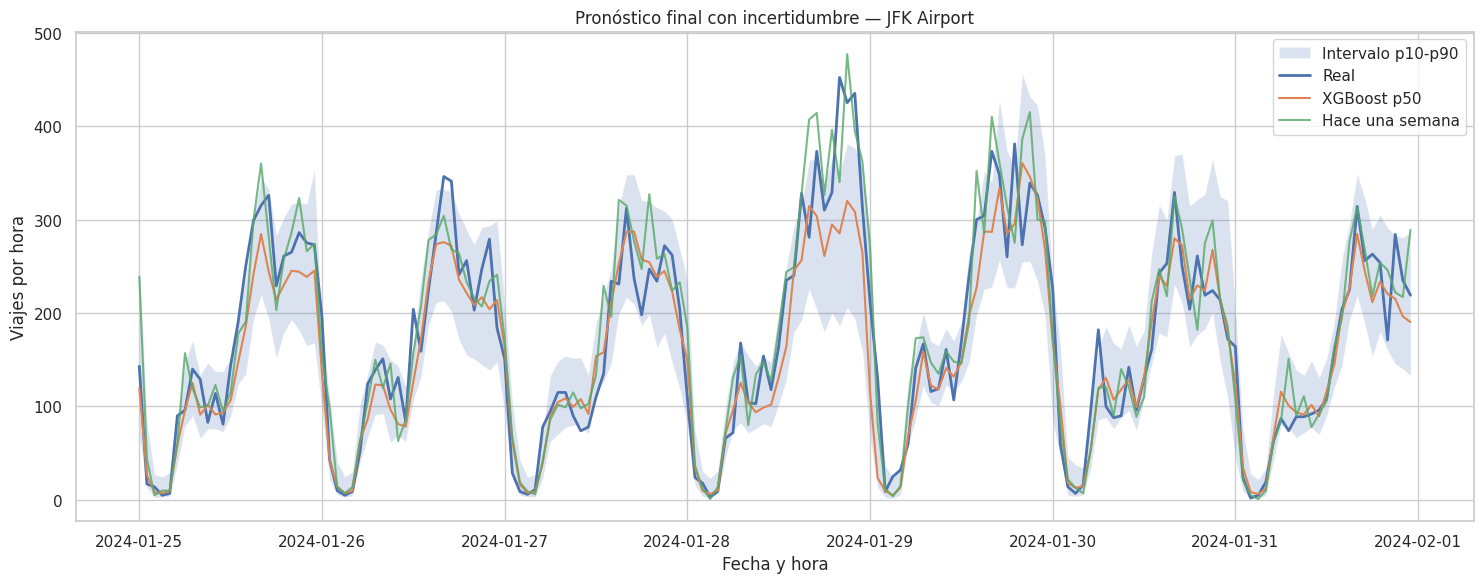

In [57]:
# ============================================================
# 56. GRÁFICA DEL PRONÓSTICO CON INCERTIDUMBRE
# ============================================================

zona_final_id = int(
    zonas_pronostico.iloc[0]["PULocationID"]
)

zona_final_nombre = (
    zonas_pronostico.iloc[0]["nombre_zona"]
)

mascara_zona = (
    test_final["PULocationID"] == zona_final_id
)

grafico_final = test_final.loc[
    mascara_zona,
    ["hora", "viajes", "lag_168"],
].copy()

grafico_final = grafico_final.join(
    predicciones_test[
        ["p10", "p50", "p90"]
    ]
)

plt.figure(figsize=(15, 6))

plt.fill_between(
    grafico_final["hora"],
    grafico_final["p10"],
    grafico_final["p90"],
    alpha=0.20,
    label="Intervalo p10-p90",
)

plt.plot(
    grafico_final["hora"],
    grafico_final["viajes"],
    label="Real",
    linewidth=2,
)

plt.plot(
    grafico_final["hora"],
    grafico_final["p50"],
    label="XGBoost p50",
)

plt.plot(
    grafico_final["hora"],
    grafico_final["lag_168"],
    label="Hace una semana",
    alpha=0.8,
)

plt.title(
    f"Pronóstico final con incertidumbre — {zona_final_nombre}"
)
plt.xlabel("Fecha y hora")
plt.ylabel("Viajes por hora")
plt.legend()
plt.tight_layout()
plt.show()


### Análisis

En **JFK Airport** se observa un patrón diario claro, con caídas pronunciadas en horas de baja actividad y picos recurrentes durante el día. El pronóstico `p50` sigue correctamente la forma general de la demanda, aunque tiende a quedarse por debajo de algunos de los picos más altos. La banda `p10–p90` cubre la mayor parte de los valores reales y se amplía en períodos de mayor demanda, reflejando una mayor incertidumbre en esas horas.


## 32. Preparación del 1 de febrero

El 1 de febrero no posee valores reales dentro del conjunto utilizado. Estas predicciones representan el caso de uso futuro de la aplicación.


In [58]:
# ============================================================
# 57. PRONÓSTICO PARA EL 1 DE FEBRERO
# ============================================================

pred_futuro = modelo_cuantiles.predict(
    X_futuro_final
)

pred_futuro = np.sort(
    pred_futuro,
    axis=1,
)

pred_futuro = np.maximum(
    pred_futuro,
    0,
)

predicciones_futuro = pd.DataFrame(
    pred_futuro,
    columns=NOMBRES_CUANTILES,
    index=futuro_final.index,
)

print(
    "Predicciones generadas para:",
    futuro_final["hora"].min(),
    "→",
    futuro_final["hora"].max(),
)

display(
    predicciones_futuro.head()
)


Predicciones generadas para: 2024-02-01 00:00:00 → 2024-02-01 23:00:00


,p10,p20,p30,p40,p50,p60,p70,p80,p90
744,0.0,0.531705,0.676359,0.797712,1.327657,1.910674,2.755945,4.373004,17.866282
745,0.0,0.431091,0.810857,1.018513,1.302841,1.516597,2.035929,3.991282,17.053217
746,0.0,0.000000,0.012119,0.125693,0.399077,0.869916,1.458129,3.037147,16.916819
747,0.0,0.000000,0.000000,0.007794,0.371970,0.820732,1.296644,2.892706,16.899847
748,0.0,0.000000,0.000000,0.007794,0.371970,0.820732,1.310090,2.892706,16.899847


## 33. Archivos para la API

La API no volverá a calcular rezagos. El notebook deja preparados:

- `modelo_pronostico.ubj`: modelo XGBoost por cuantiles;
- `demanda.parquet`: filas del 25 de enero al 1 de febrero con sus variables ya calculadas;
- `info_modelo.json`: variables, cuantiles y categorías necesarias para cargar el modelo correctamente;
- `metricas_modelo_final.csv`: métricas que se reutilizarán en la ficha del modelo.


In [59]:
# ============================================================
# 58. GUARDAR EL MODELO FINAL
# ============================================================

modelo_cuantiles.save_model(
    "modelo_pronostico.ubj"
)

print(
    "✅ Archivo generado: modelo_pronostico.ubj"
)


✅ Archivo generado: modelo_pronostico.ubj


In [60]:
# ============================================================
# 59. PREPARAR demanda.parquet PARA LA API
# ============================================================

demanda_api = datos_finales[
    (
        datos_finales["hora"]
        >= pd.Timestamp("2024-01-25")
    )
    & (
        datos_finales["hora"]
        < pd.Timestamp("2024-02-02")
    )
].copy()

# Se conserva el valor real cuando existe.
# Para el 1 de febrero permanece como NaN.
columnas_api = [
    "PULocationID",
    "hora",
    "viajes",
] + VARIABLES_FINALES

# Eliminamos posibles nombres repetidos.
columnas_api = list(
    dict.fromkeys(columnas_api)
)

demanda_api = demanda_api[
    columnas_api
].copy()

demanda_api.to_parquet(
    "demanda.parquet",
    index=False,
)

print(
    "✅ Archivo generado: demanda.parquet"
)
print(
    f"Filas exportadas: {len(demanda_api):,}"
)

display(
    demanda_api.tail()
)


✅ Archivo generado: demanda.parquet
Filas exportadas: 11,136


,PULocationID,hora,viajes,lag_24,lag_48,lag_167,lag_168,lag_169,media_dia_ant,hora_dia,dia_semana,feriado,zona
44539,263,2024-02-01 19:00:00,NaN,106.0,115.0,110.0,84.0,140.0,80.833333,19,3,0,263
44540,263,2024-02-01 20:00:00,NaN,104.0,99.0,104.0,110.0,84.0,80.833333,20,3,0,263
44541,263,2024-02-01 21:00:00,NaN,92.0,96.0,85.0,104.0,110.0,80.833333,21,3,0,263
44542,263,2024-02-01 22:00:00,NaN,80.0,63.0,66.0,85.0,104.0,80.833333,22,3,0,263
44543,263,2024-02-01 23:00:00,NaN,53.0,42.0,36.0,66.0,85.0,80.833333,23,3,0,263


In [61]:
# ============================================================
# 60. INFORMACIÓN NECESARIA PARA CARGAR EL MODELO
# ============================================================

import json

info_modelo = {
    "variables": VARIABLES_FINALES,
    "cuantiles": [
        float(q)
        for q in CUANTILES
    ],
    "nombres_cuantiles": NOMBRES_CUANTILES,
    "categorias_zonas": categorias_zonas,
    "fecha_inicio_prueba": "2024-01-25",
    "fecha_fin_prueba": "2024-01-31",
    "fecha_futura": "2024-02-01",
}

with open(
    "info_modelo.json",
    "w",
    encoding="utf-8",
) as archivo:
    json.dump(
        info_modelo,
        archivo,
        ensure_ascii=False,
        indent=2,
    )

print(
    "✅ Archivo generado: info_modelo.json"
)


✅ Archivo generado: info_modelo.json


In [62]:
# ============================================================
# 61. EXPORTAR MÉTRICAS DEL MODELO FINAL
# ============================================================

metricas_modelo_final = pd.DataFrame({
    "metrica": [
        "mae_baseline_semanal",
        "rmse_baseline_semanal",
        "mae_xgboost_p50",
        "rmse_xgboost_p50",
        "cobertura_p10_p90",
        "ancho_medio_p10_p90",
    ],
    "valor": [
        mae_baseline_final,
        rmse_baseline_final,
        mae_final,
        rmse_final,
        cobertura_80,
        ancho_medio_intervalo,
    ],
})

metricas_modelo_final.to_csv(
    "metricas_modelo_final.csv",
    index=False,
)

display(
    metricas_modelo_final.round(4)
)

print(
    "✅ Archivo generado: metricas_modelo_final.csv"
)


,metrica,valor
0,mae_baseline_semanal,11.8818
1,rmse_baseline_semanal,21.8788
2,mae_xgboost_p50,11.8875
3,rmse_xgboost_p50,22.4531
4,cobertura_p10_p90,0.8998
5,ancho_medio_p10_p90,49.6081


✅ Archivo generado: metricas_modelo_final.csv


## 34. Verificación final de la Parte 3

Antes de llevar el modelo a FastAPI se realizan comprobaciones básicas sobre los archivos y las predicciones.


In [63]:
# ============================================================
# 62. VERIFICACIONES FINALES
# ============================================================

# Deben existir nueve cuantiles.
assert len(CUANTILES) == 9

# Las predicciones deben tener una columna por cuantil.
assert pred_cuantiles.shape[1] == 9
assert pred_futuro.shape[1] == 9

# Después de ordenar, ningún cuantil puede quedar por debajo
# del anterior.
assert np.all(
    np.diff(
        pred_cuantiles,
        axis=1,
    ) >= 0
)

# El futuro debe contener 24 horas por cada zona pronosticable.
assert len(futuro_final) == (
    len(ids_zonas) * 24
)

# El 1 de febrero no debe tener valores reales.
assert futuro_final["viajes"].isna().all()

print("✅ Verificaciones completadas correctamente.")
print(f"MAE final p50: {mae_final:.2f}")
print(f"MAE baseline:  {mae_baseline_final:.2f}")
print(f"Cobertura p10-p90: {cobertura_80:.2%}")
print(f"Zonas pronosticables: {len(ids_zonas)}")


✅ Verificaciones completadas correctamente.
MAE final p50: 11.89
MAE baseline:  11.88
Cobertura p10-p90: 89.98%
Zonas pronosticables: 58


# ✅ Resultado esperado de esta etapa

Al ejecutar completamente esta sección deben quedar listos los archivos necesarios para convertir la API mínima en la API final:

- `modelo_pronostico.ubj`
- `demanda.parquet`
- `info_modelo.json`
- `metricas_modelo_final.csv`

El siguiente paso consiste en colocar los tres primeros archivos dentro de `api/`, actualizar `main.py` con el endpoint `/pronostico` y después construir las páginas **Pronóstico** y **Decisión** en Streamlit.
